In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D 
from matplotlib import gridspec

import seaborn as sns


plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 14
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font for font in 'Liberation Sans, DejaVu Sans, Arial, Helvetica, Lucida Grande, Verdana, Geneva, Lucid, Avant Garde, sans-serif'.split(', ')] 
plt.rcParams['mathtext.fontset'] = 'stixsans'

plt.rcParams['axes.linewidth'] = 1
plt.rcParams['grid.linewidth'] = 1
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 6


In [2]:
cat_colors_list = [ '#263238','#2E5BFF', "#D4AF37", '#D81B60', '#558B2F', '#7B1FA2', '#E65100']  # ,   '#94A3B8' 
unique_categories = ['common',  'SADE unique', 'CR unique', 'TSS unique',  'SADE+CR, not TSS', 'SADE+TSS, not CR', 'CR+TSS, not SADE', ]
cat_colors_map = dict(zip(unique_categories, cat_colors_list))    


# Load

In [3]:
## Downloaded CR-arc count matrix results
data_dir = '/mnt/hdd_bob/syy/adipose/atac/protocol_benchmark/downloaded_counts/VIB_10xmultiome_2'

## Entropy filtered atac
entropy_dir = '/mnt/hdd_bob/syy/adipose/atac/res/VIB_10xmultiome_2_WS3000F'
union_cells_dir = os.path.join(entropy_dir, '_cell_calling_comparison')

# Load peak annotations [including peak AUC score from Genrich peaks]
# Raw peaks are inferred with all reads 
raw_peaks_annot = pd.read_csv(os.path.join(union_cells_dir, 'Rawpeaks/annotation', 'annotated_peaks.bed'),      sep='\t')
raw_peaks_annot['peak_size'] = raw_peaks_annot['End'] - raw_peaks_annot['Start']

# Common peaks are inferred with the common droplets from 3 nuclei-filtering sets (SADE, CR, TSSe)
common_peaks_annot_file = os.path.join(union_cells_dir, 'Commoncells_peaks/annotation', 'annotated_peaks.bed')
common_peaks_annot = pd.read_csv(common_peaks_annot_file, sep='\t')
common_peaks_annot['peak_size'] = common_peaks_annot['End'] - common_peaks_annot['Start']

sade_peaks_annot_file = os.path.join(union_cells_dir, 'Entropy_cells_peaks/annotation/', 'annotated_peaks.bed')
cr_peaks_annot_file = os.path.join(union_cells_dir, 'FRIP_cells_peaks/annotation/', 'annotated_peaks.bed')
tsse_peaks_annot_file = os.path.join(union_cells_dir, 'TSS_cells_peaks/annotation/', 'annotated_peaks.bed')


SADE_vs_raw_annot_sudir = os.path.join(union_cells_dir, 'Entropypeaks_vs_Rawpeaks/annotation')
CR_vs_raw_annot_sudir = os.path.join(union_cells_dir, 'FRIPpeaks_vs_Rawpeaks/annotation')
TSSe_vs_raw_annot_sudir = os.path.join(union_cells_dir, 'TSSpeaks_vs_Rawpeaks/annotation')
common_vs_raw_annot_sudir = os.path.join(union_cells_dir, 'Commonpeaks_vs_Rawpeaks/annotation')

SADE_vs_raw = {}
CR_vs_raw = {}
TSSe_vs_raw = {}
common_vs_raw = {}

for tf, p, d in zip([sade_peaks_annot_file, cr_peaks_annot_file, tsse_peaks_annot_file, common_peaks_annot_file],
    [SADE_vs_raw_annot_sudir, CR_vs_raw_annot_sudir, TSSe_vs_raw_annot_sudir, common_vs_raw_annot_sudir],
                [SADE_vs_raw, CR_vs_raw, TSSe_vs_raw, common_vs_raw]):
    d['whole_peak_set'] = pd.read_csv(tf, sep='\t')
    d['whole_peak_set']['peak_size'] = d['whole_peak_set']['End'] - d['whole_peak_set']['Start']
    
    d['dropped_peaks'] = pd.read_csv(os.path.join(p, 'annotated_lost_peaks.bed'), sep='\t')
    d['newly_discovered_peaks'] = pd.read_csv(os.path.join(p, 'annotated_newly_discovered_peaks.bed'), sep='\t')
    
    d['dropped_peaks']['peak_size'] = d['dropped_peaks']['End'] - d['dropped_peaks']['Start']
    d['newly_discovered_peaks']['peak_size'] = d['newly_discovered_peaks']['End'] - d['newly_discovered_peaks']['Start']
    

----

In [4]:
# Load peak annotations (cCREs)
cCREs_columns = ['chrom', 'chromStart', 'chromEnd', 'name', 'peak_auc_score', 'strand', 'signalValue', 'pValue', 'qValue', 'peak', 
           'cCREs_chrom', 'cCREs_start', 'cCREs_end', 'cCREs_acessionID1', 'cCREs_accessionID2', 'cCREs_class', 'overlap_bp']
# Raw peaks are inferred with all reads 
raw_peaks_cCREs_sudir = os.path.join(union_cells_dir, 'Rawpeaks/cCRE_annotation')
raw_peaks_cCREs_file = os.path.join(union_cells_dir, 'Rawpeaks/cCRE_annotation', 'cCRE_annot_peaks.bed')


# Common peaks are inferred with the common droplets from 3 nuclei-filtering sets (SADE, CR, TSSe)
common_peaks_cCREs_file = os.path.join(union_cells_dir, 'Commoncells_peaks/cCRE_annotation', 'cCRE_annot_peaks.bed')
common_peaks_cCREs = pd.read_csv(common_peaks_cCREs_file, sep='\t')
common_peaks_cCREs.columns = cCREs_columns


sade_peaks_cCREs_file = os.path.join(union_cells_dir, 'Entropy_cells_peaks/cCRE_annotation/', 'cCRE_annot_peaks.bed')
cr_peaks_cCREs_file = os.path.join(union_cells_dir, 'FRIP_cells_peaks/cCRE_annotation/', 'cCRE_annot_peaks.bed')
tsse_peaks_cCREs_file = os.path.join(union_cells_dir, 'TSS_cells_peaks/cCRE_annotation/', 'cCRE_annot_peaks.bed')


SADE_vs_raw_cCREs_sudir = os.path.join(union_cells_dir, 'Entropypeaks_vs_Rawpeaks/cCRE_annotation')
CR_vs_raw_cCREs_sudir = os.path.join(union_cells_dir, 'FRIPpeaks_vs_Rawpeaks/cCRE_annotation')
TSSe_vs_raw_cCREs_sudir = os.path.join(union_cells_dir, 'TSSpeaks_vs_Rawpeaks/cCRE_annotation')
common_vs_raw_cCREs_sudir = os.path.join(union_cells_dir, 'Commonpeaks_vs_Rawpeaks/cCRE_annotation')

raw_peaks_cCREs = {}
SADE_vs_raw_cCREs = {}
CR_vs_raw_cCREs = {}
TSSe_vs_raw_cCREs = {}
common_vs_raw_cCREs = {}

for tf, p, d in zip([raw_peaks_cCREs_file, sade_peaks_cCREs_file, cr_peaks_cCREs_file, tsse_peaks_cCREs_file, common_peaks_cCREs_file],
    [raw_peaks_cCREs_sudir, SADE_vs_raw_cCREs_sudir, CR_vs_raw_cCREs_sudir, TSSe_vs_raw_cCREs_sudir, common_vs_raw_cCREs_sudir],
                [raw_peaks_cCREs, SADE_vs_raw_cCREs, CR_vs_raw_cCREs, TSSe_vs_raw_cCREs, common_vs_raw_cCREs]):
    d['whole_peak_set'] = pd.read_csv(tf, sep='\t')
    d['whole_peak_set'].columns = cCREs_columns
    
    if tf == raw_peaks_cCREs_file:
        continue
    d['dropped_peaks'] = pd.read_csv(os.path.join(p, 'cCRE_annot_lost_peaks.bed'), sep='\t')
    d['newly_discovered_peaks'] = pd.read_csv(os.path.join(p, 'cCRE_annot_newly_discovered_peaks.bed'), sep='\t')
    
    d['dropped_peaks'].columns = cCREs_columns
    d['newly_discovered_peaks'].columns = cCREs_columns

In [5]:
# Load peak annotations (cCREs)
cCREs_columns = ['chrom', 'chromStart', 'chromEnd', 'name', 'peak_auc_score', 'strand', 'signalValue', 'pValue', 'qValue', 'peak', 
           'cCREs_chrom', 'cCREs_start', 'cCREs_end', 'cCREs_acessionID1', 'cCREs_accessionID2', 'cCREs_class', 'overlap_bp']

# Common peaks are inferred with the common droplets from 3 nuclei-filtering sets (SADE, CR, TSSe)
common_peaks_cCREs_file = os.path.join(union_cells_dir, 'Commoncells_peaks/cCRE_annotation', 'cCRE_annot_peaks.bed')
common_peaks_cCREs = pd.read_csv(common_peaks_cCREs_file, sep='\t')
common_peaks_cCREs.columns = cCREs_columns


sade_peaks_cCREs_file = os.path.join(union_cells_dir, 'Entropy_cells_peaks/cCRE_annotation/', 'cCRE_annot_peaks.bed')
cr_peaks_cCREs_file = os.path.join(union_cells_dir, 'FRIP_cells_peaks/cCRE_annotation/', 'cCRE_annot_peaks.bed')
tsse_peaks_cCREs_file = os.path.join(union_cells_dir, 'TSS_cells_peaks/cCRE_annotation/', 'cCRE_annot_peaks.bed')


SADE_vs_common_cCREs_sudir = os.path.join(union_cells_dir, 'Entropypeaks_vs_Commonpeaks/cCRE_annotation')
CR_vs_common_cCREs_sudir = os.path.join(union_cells_dir, 'FRIPpeaks_vs_Commonpeaks/cCRE_annotation')
TSSe_vs_common_cCREs_sudir = os.path.join(union_cells_dir, 'TSSpeaks_vs_Commonpeaks/cCRE_annotation')

SADE_vs_common_cCREs = {}
CR_vs_common_cCREs = {}
TSSe_vs_common_cCREs = {}

for tf, p, d in zip([sade_peaks_cCREs_file, cr_peaks_cCREs_file, tsse_peaks_cCREs_file],
    [SADE_vs_common_cCREs_sudir, CR_vs_common_cCREs_sudir, TSSe_vs_common_cCREs_sudir],
                [SADE_vs_common_cCREs, CR_vs_common_cCREs, TSSe_vs_common_cCREs]):
    d['whole_peak_set'] = pd.read_csv(tf, sep='\t')
    
    d['dropped_peaks'] = pd.read_csv(os.path.join(p, 'cCRE_annot_lost_peaks.bed'), sep='\t')
    d['newly_discovered_peaks'] = pd.read_csv(os.path.join(p, 'cCRE_annot_newly_discovered_peaks.bed'), sep='\t')
    
    d['whole_peak_set'].columns = cCREs_columns
    d['dropped_peaks'].columns = cCREs_columns
    d['newly_discovered_peaks'].columns = cCREs_columns

In [6]:
SADE_vs_raw_cCREs['dropped_peaks'].head()


,chrom,chromStart,chromEnd,name,peak_auc_score,strand,signalValue,pValue,qValue,peak,cCREs_chrom,cCREs_start,cCREs_end,cCREs_acessionID1,cCREs_accessionID2,cCREs_class,overlap_bp
0,chr1,144104205,144104694,peak_1780,548,.,267.775543,3.103723,-1,443,chr1,144104433,144104706,EH38D4417319,EH38E2835309,dELS,261
1,KI270442.1,391172,392051,peak_32786,542,.,476.026672,3.399083,-1,234,.,-1,-1,.,.,.,0
2,KI270729.1,1155,1849,peak_32787,1000,.,771.622559,4.155765,-1,386,.,-1,-1,.,.,.,0
3,KI270729.1,2175,3710,peak_32788,1000,.,3725.948242,5.831364,-1,959,.,-1,-1,.,.,.,0
4,KI270729.1,4062,5209,peak_32789,1000,.,1956.790161,5.308810,-1,781,.,-1,-1,.,.,.,0


# Plot

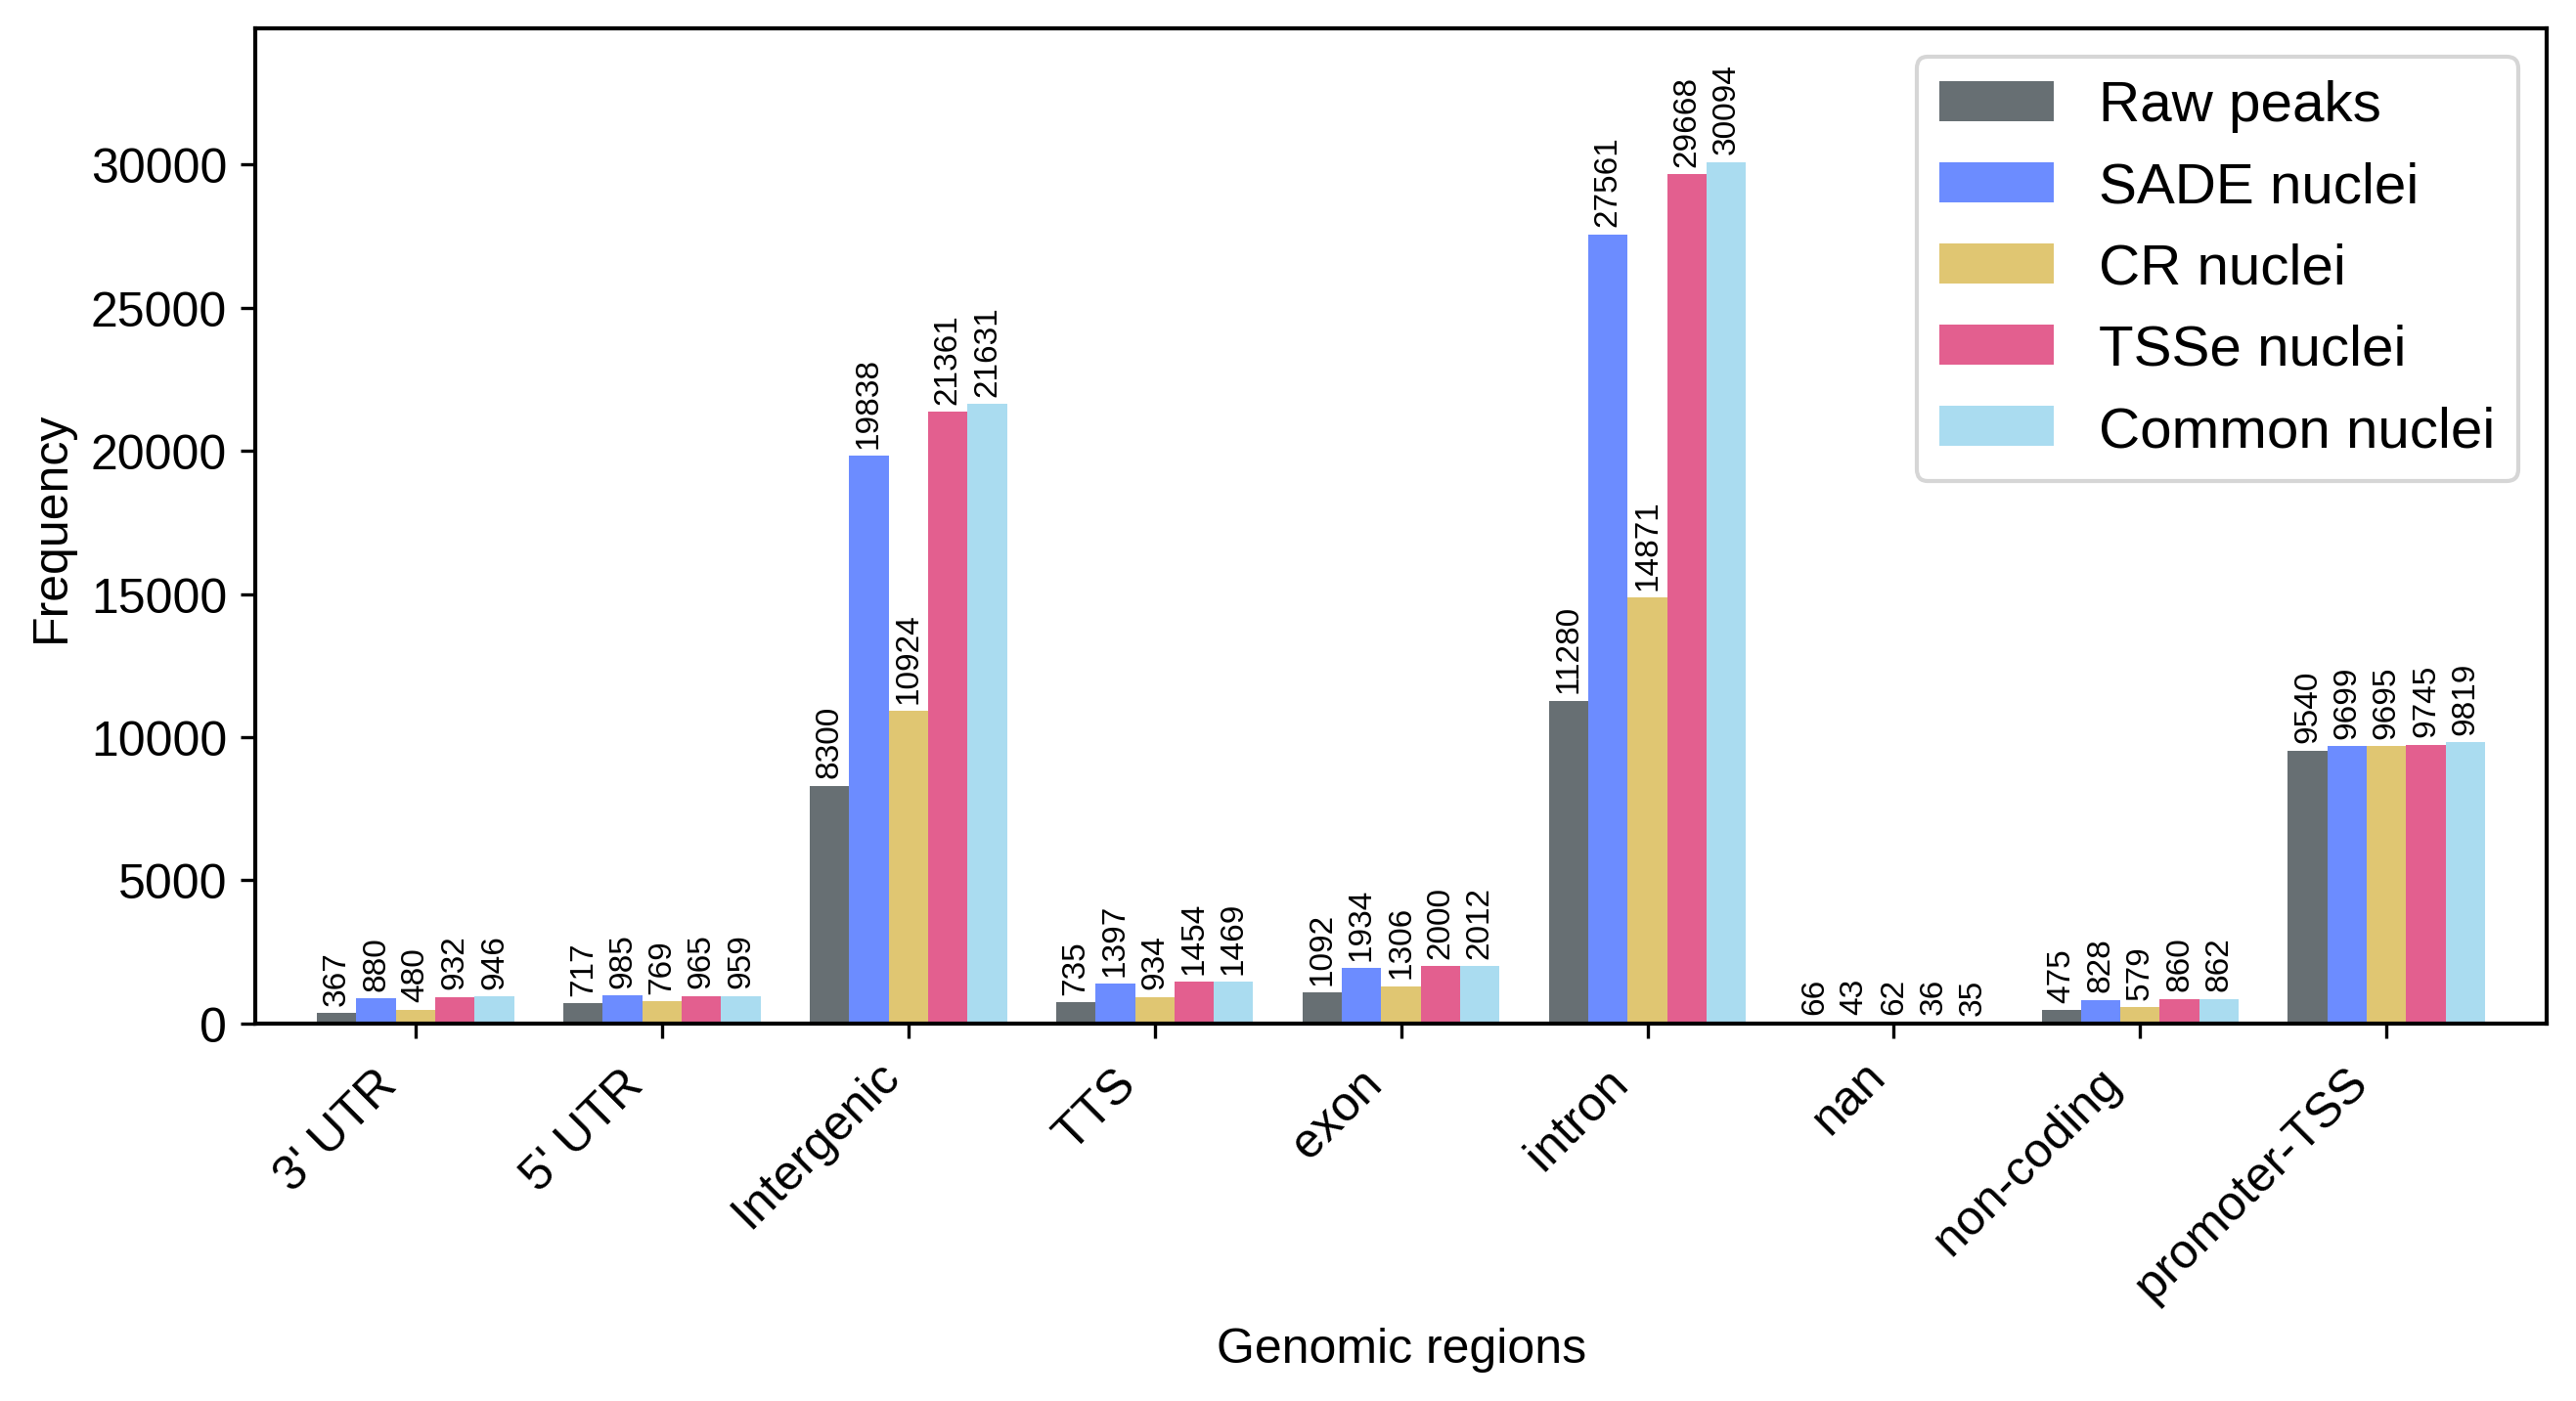

In [7]:
def simplify_annotation(annot_df, inplace=False):
    """
    Simplify the Annotation column.
    """
    if not inplace:
        annot_df = annot_df.copy()
        simple_annotation = annot_df['Annotation'].apply(lambda x: str(x).split('(')[0])  
        return simple_annotation
    else:
        # in place change of the  DataFrame
        annot_df['simple_annotation'] = annot_df['Annotation'].apply(lambda x: str(x).split('(')[0])  
        
simplify_annotation(raw_peaks_annot, inplace=True)
simplify_annotation(SADE_vs_raw['whole_peak_set'], inplace=True)
simplify_annotation(CR_vs_raw['whole_peak_set'], inplace=True)
simplify_annotation(TSSe_vs_raw['whole_peak_set'], inplace=True)
simplify_annotation(common_vs_raw['whole_peak_set'], inplace=True)

        
raw_peak_freq = raw_peaks_annot['simple_annotation'].value_counts()
sade_peak_freq = SADE_vs_raw['whole_peak_set']['simple_annotation'].value_counts()
cr_peak_freq = CR_vs_raw['whole_peak_set']['simple_annotation'].value_counts()
tsse_peak_freq = TSSe_vs_raw['whole_peak_set']['simple_annotation'].value_counts()
common_peak_freq = common_vs_raw['whole_peak_set']['simple_annotation'].value_counts()

freq_df = pd.DataFrame({
    'Raw peaks': raw_peak_freq,
    'SADE nuclei': sade_peak_freq,
    'CR nuclei': cr_peak_freq,
    'TSSe nuclei': tsse_peak_freq,
    'Common nuclei': common_peak_freq
}).fillna(0)

fig, ax = plt.subplots(figsize=(9, 5))
freq_df.plot(kind='bar', width=0.8, alpha=0.7, ax=ax, color=[ '#263238','#2E5BFF', "#D4AF37", '#D81B60', 'skyblue'], fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=2, fontsize=8, rotation=90 )


ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_xlabel('Genomic regions', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_ylabel('Frequency', fontsize=12)
ax.legend()
fig.tight_layout()

[Text(0, 0, 'intron '),
 Text(1, 0, 'promoter-TSS '),
 Text(2, 0, 'Intergenic'),
 Text(3, 0, 'exon '),
 Text(4, 0, "5' UTR "),
 Text(5, 0, 'TTS '),
 Text(6, 0, 'non-coding '),
 Text(7, 0, "3' UTR "),
 Text(8, 0, 'nan')]

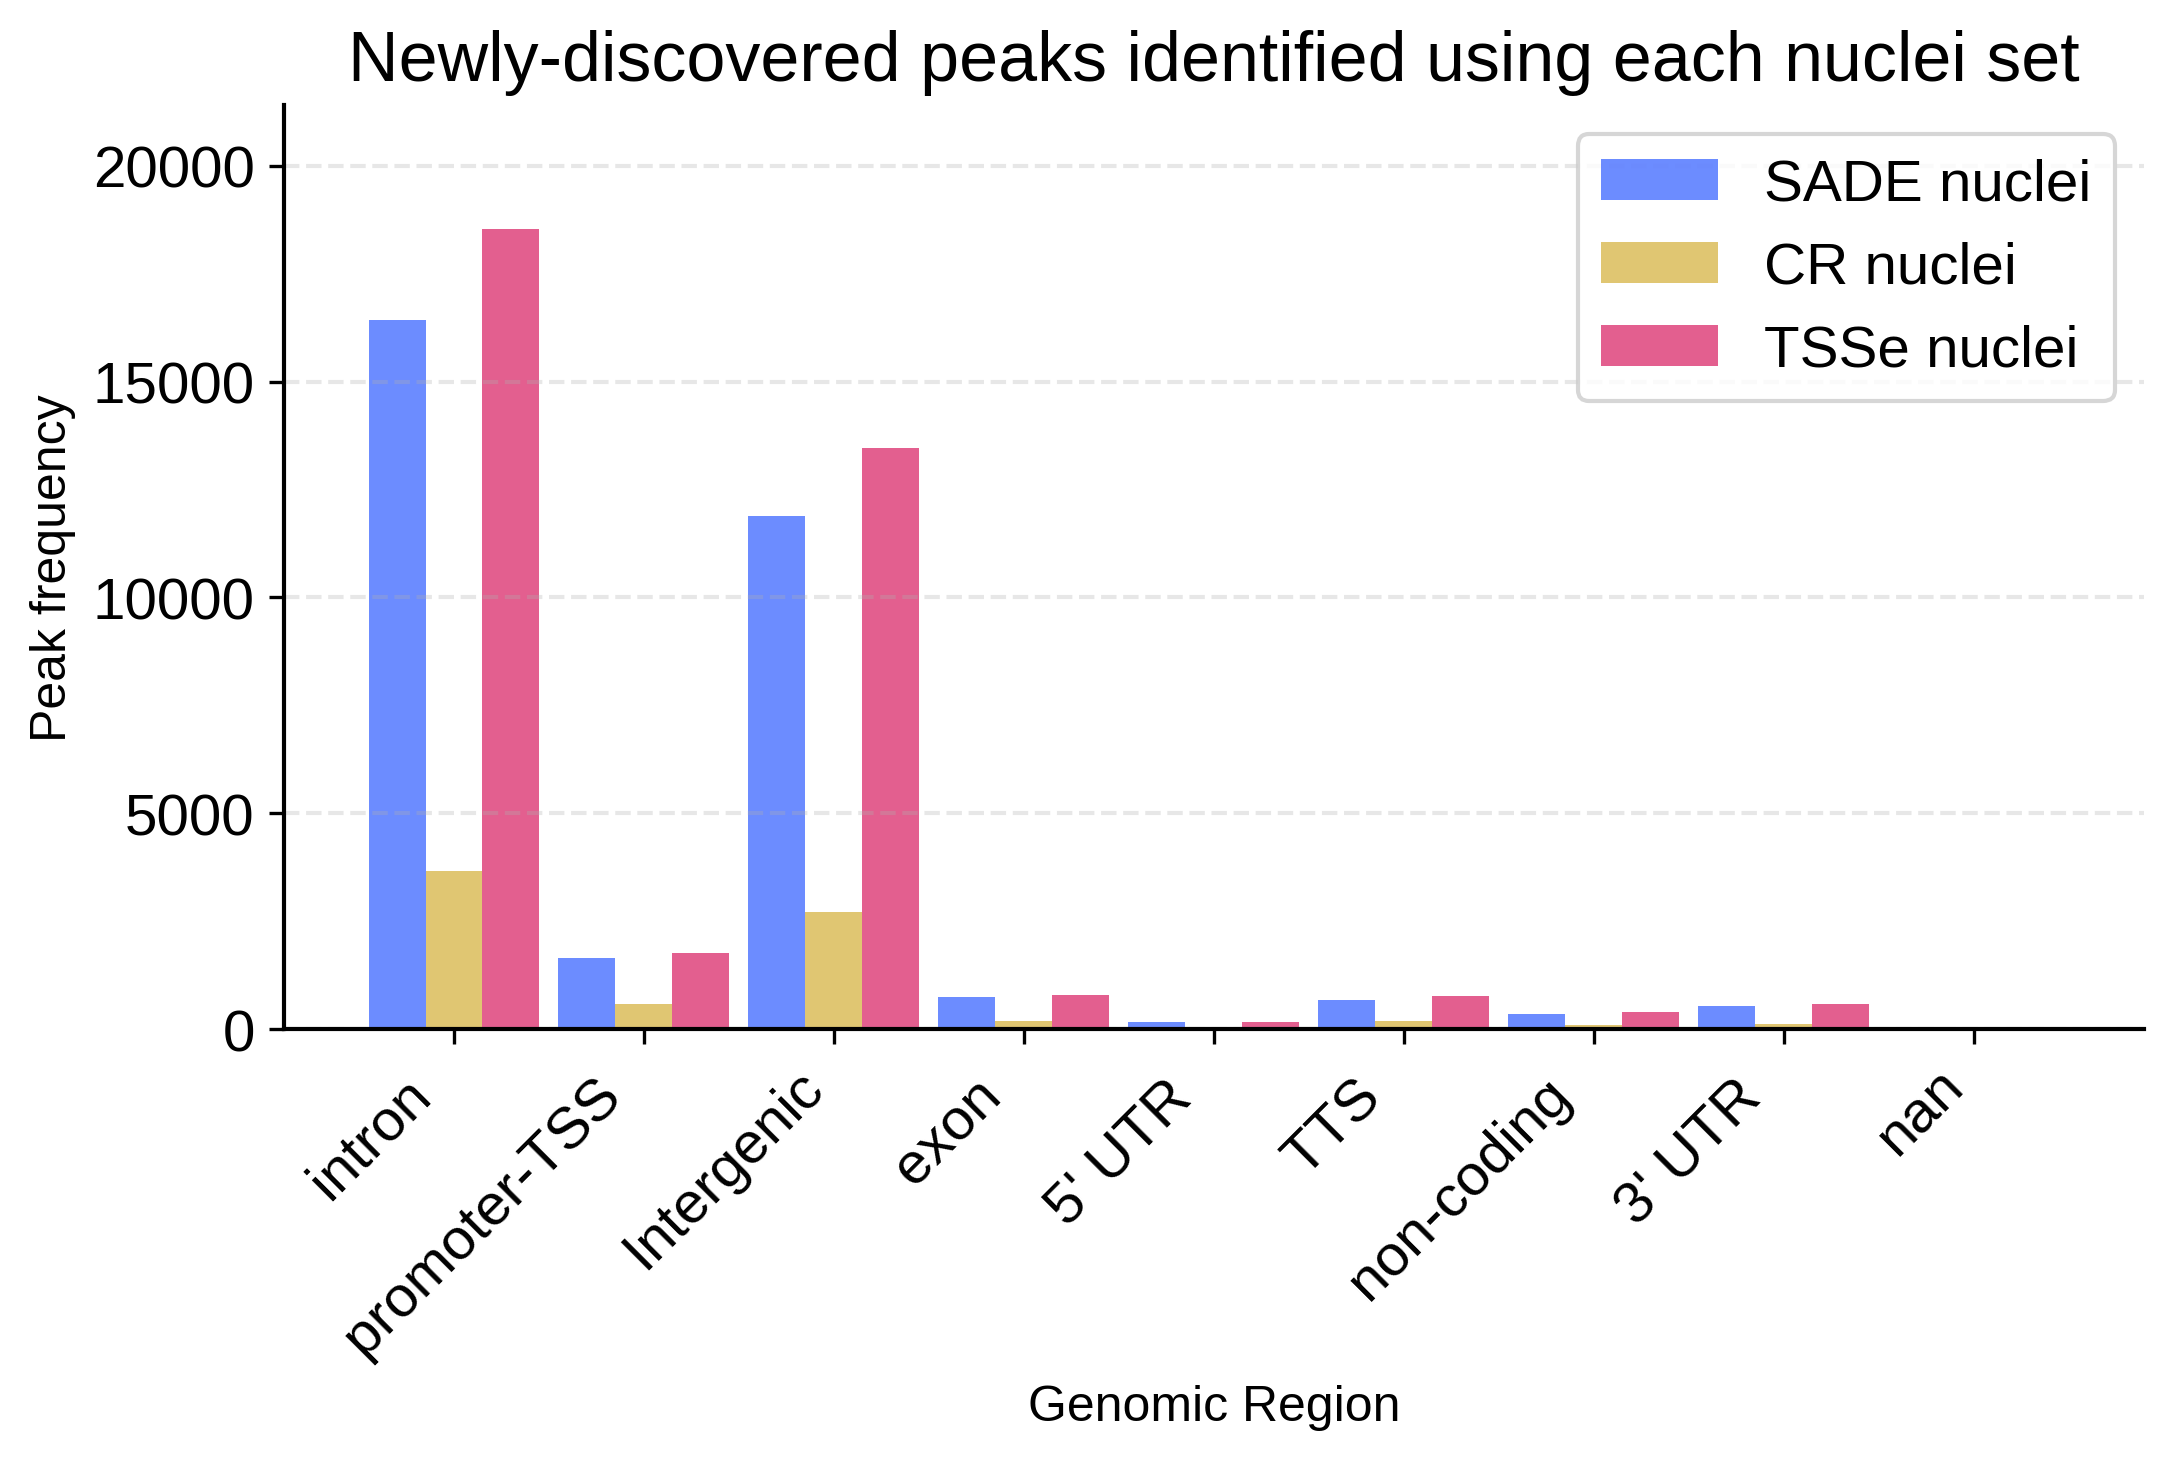

In [8]:
color_map = {'intron ': 'blue', 'promoter-TSS ': 'orange', 'Intergenic': 'skyblue', 'exon ': 'red',
                "5' UTR ": 'purple', 'TTS ': 'brown', 'non-coding ': 'pink', "3' UTR ": 'slateblue', 'nan': 'grey'}
index_map = {'intron ': 0, 'promoter-TSS ': 1, 'Intergenic': 2, 'exon ': 3,
                "5' UTR ": 4, 'TTS ': 5, 'non-coding ': 6, "3' UTR ": 7, 'nan': 8}

width = 0.3  # the width of the bars
fig, ax = plt.subplots( nrows=1, ncols=1, figsize=(8,4))

for d, c, poffset, l in zip([SADE_vs_raw, CR_vs_raw, TSSe_vs_raw], ['#2E5BFF', "#D4AF37", '#D81B60'],
                    0.3*np.array([-1, 0, 1]),
                    ['SADE nuclei', 'CR nuclei', 'TSSe nuclei']):
    freq_df = simplify_annotation(d['newly_discovered_peaks'], inplace=False).value_counts()
    x_positions = [index_map[idx] + poffset for idx in freq_df.index]
    ax.bar(x_positions, freq_df.values, width=0.3, alpha=0.7, color=c, label=f'{l}')


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_ylabel('Peak frequency', fontsize=12)
ax.set_xlabel('Genomic Region', fontsize=12) 
ax.legend(loc='upper right', ncols=1, bbox_to_anchor=(1, 1))
ax.set_title('Newly-discovered peaks identified using each nuclei set')


ticks = sorted(index_map.values())
labels = sorted(index_map, key=index_map.get)
ax.set_xticks(ticks)
ax.set_xticklabels(labels, rotation=45, ha='right')


[Text(0, 0, 'High-CA cCREs'),
 Text(1, 0, 'Low-CA cCREs'),
 Text(2, 0, 'Missing cCREs')]

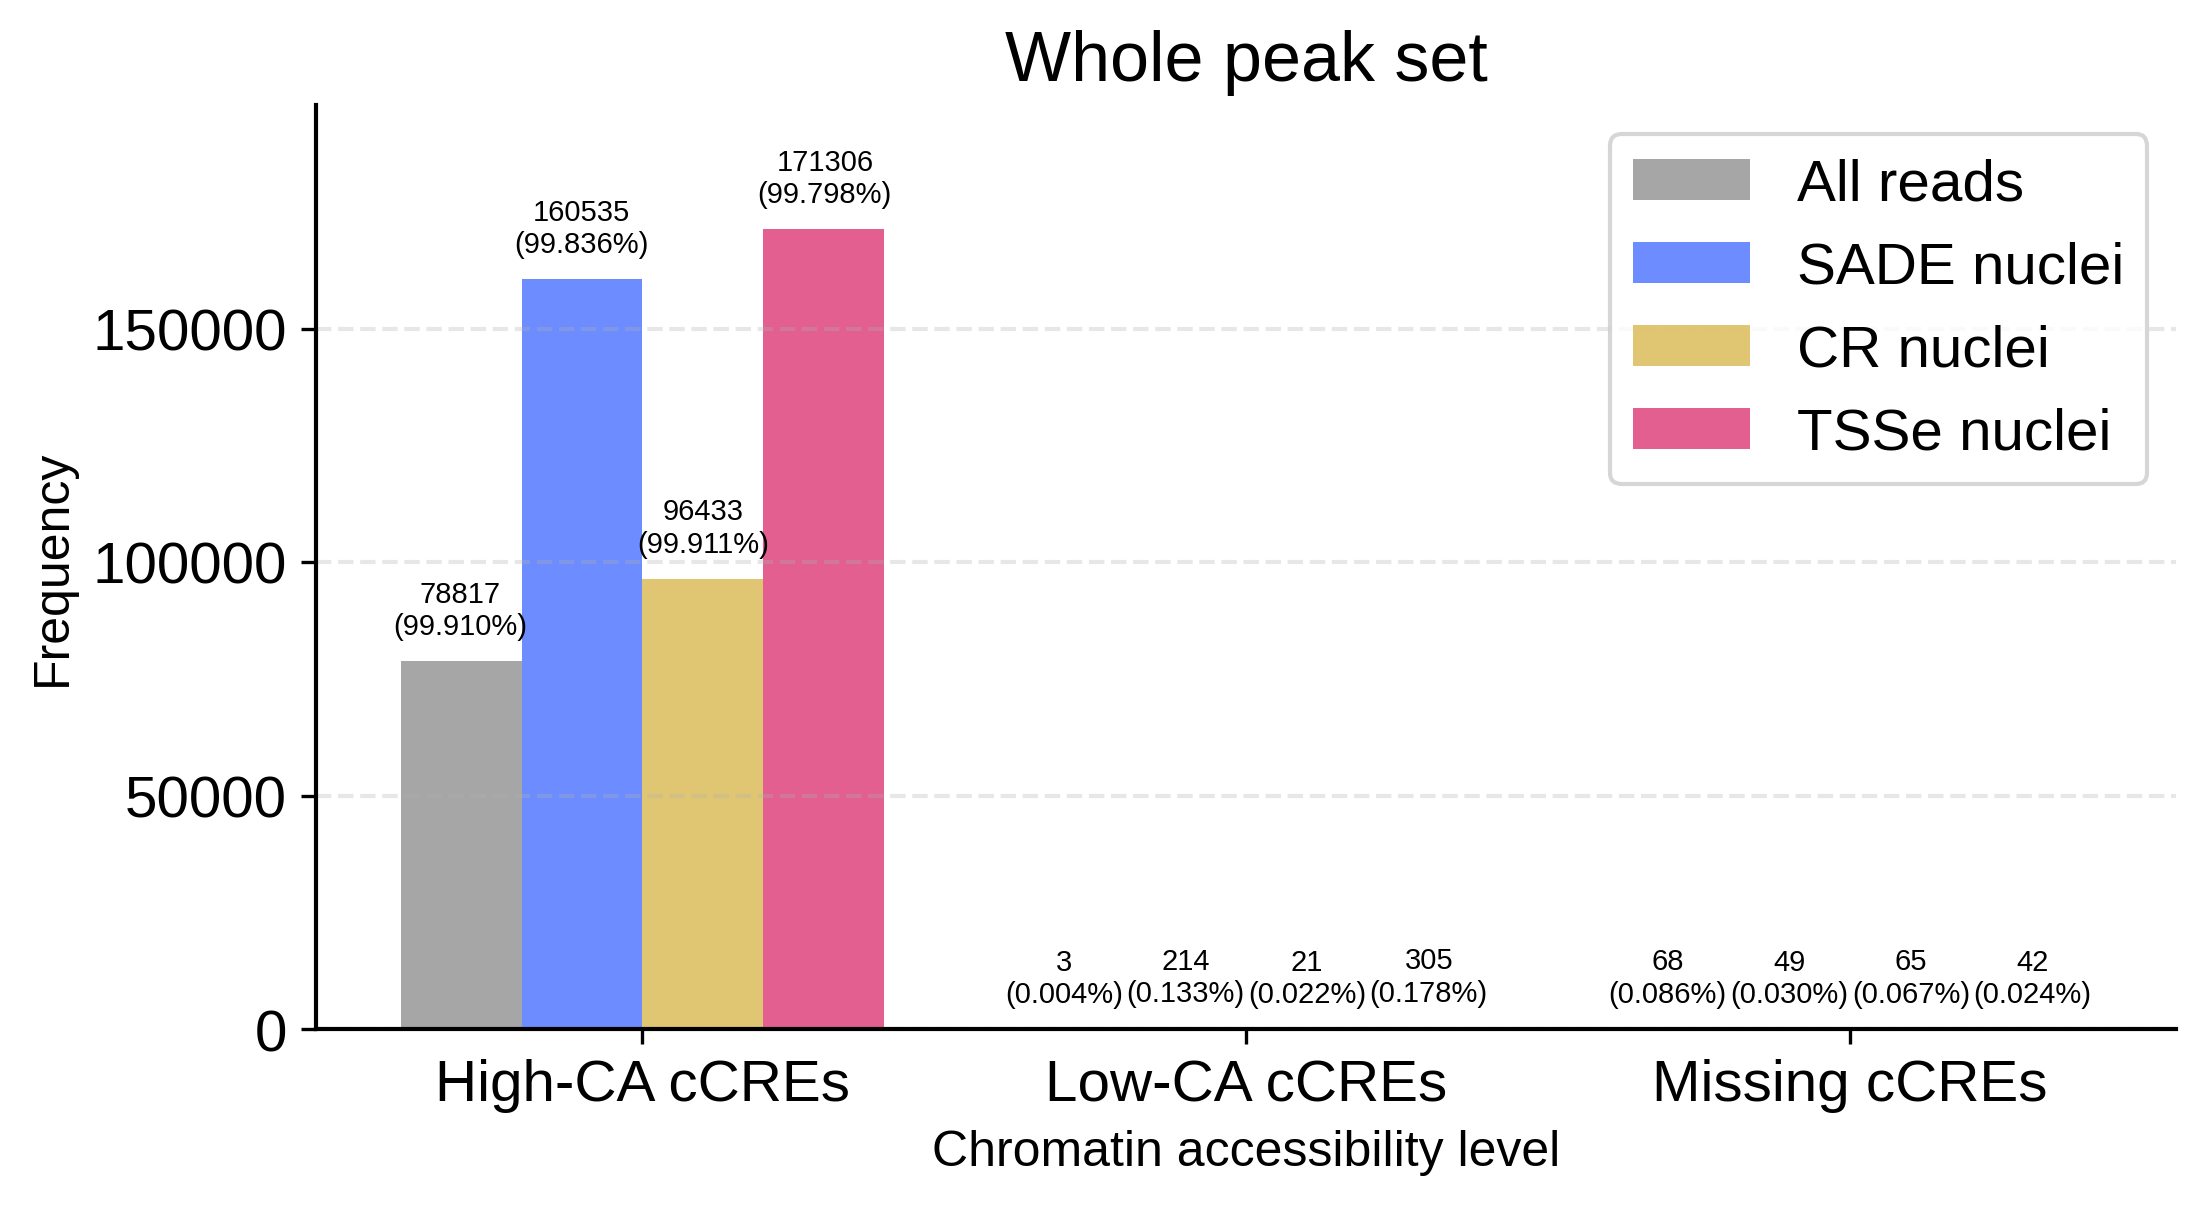

In [36]:
CA_level_color_map = {'High-CA cCREs': 'blue', 'Low-CA cCREs': 'orange', 'Missing cCREs': 'grey'}
CA_level_index_map = {'High-CA cCREs': 0, 'Low-CA cCREs': 1, 'Missing cCREs': 2}
CA_regions_level = {'dELS': 'High-CA cCREs', 'pELS': 'High-CA cCREs', 'PLS': 'High-CA cCREs', 'CA-H3K4me3': 'High-CA cCREs',
                "CA-CTCF": 'High-CA cCREs', 'CA-TF': 'High-CA cCREs', 'TF': 'Low-CA cCREs', "CA": 'High-CA cCREs', '.': 'Missing cCREs'}

width = 0.2  # the width of the bars
fig, ax = plt.subplots( nrows=1, ncols=1, figsize=(8,4))

for d, c, poffset, l in zip([raw_peaks_cCREs, SADE_vs_raw_cCREs, CR_vs_raw_cCREs,   TSSe_vs_raw_cCREs], ['grey', '#2E5BFF', "#D4AF37",  '#D81B60', ],
                    width*np.array([-1.5, -0.5, 0.5, 1.5]),
                    ['All reads', 'SADE nuclei','CR nuclei', 'TSSe nuclei']):
    freq_df = d['whole_peak_set'].dropna(subset=['cCREs_class'], inplace=False
                                         )['cCREs_class'].map(CA_regions_level).value_counts()
    percent = freq_df / freq_df.sum() * 100
    x_positions = [CA_level_index_map[idx] + poffset for idx in freq_df.index]
    bars = ax.bar(x_positions, freq_df.values, width=width, alpha=0.7, color=c, label=f'{l}')
    for bar, class_name in zip(bars, freq_df.index):
        ax.annotate(
            f'{freq_df[class_name]}\n({percent[class_name]:.3f}%)',
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0 +  poffset, 5 ),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=7,
            rotation=0
        )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_xlabel('Chromatin accessibility level', fontsize=12) 
ax.legend(loc='upper right', ncols=1, bbox_to_anchor=(1, 1))
ax.set_title('Whole peak set')


ticks = sorted(CA_level_index_map.values())
labels = sorted(CA_level_index_map, key=CA_level_index_map.get)
ax.set_xticks(ticks)
ax.set_xticklabels(labels, rotation=0, ha='center')

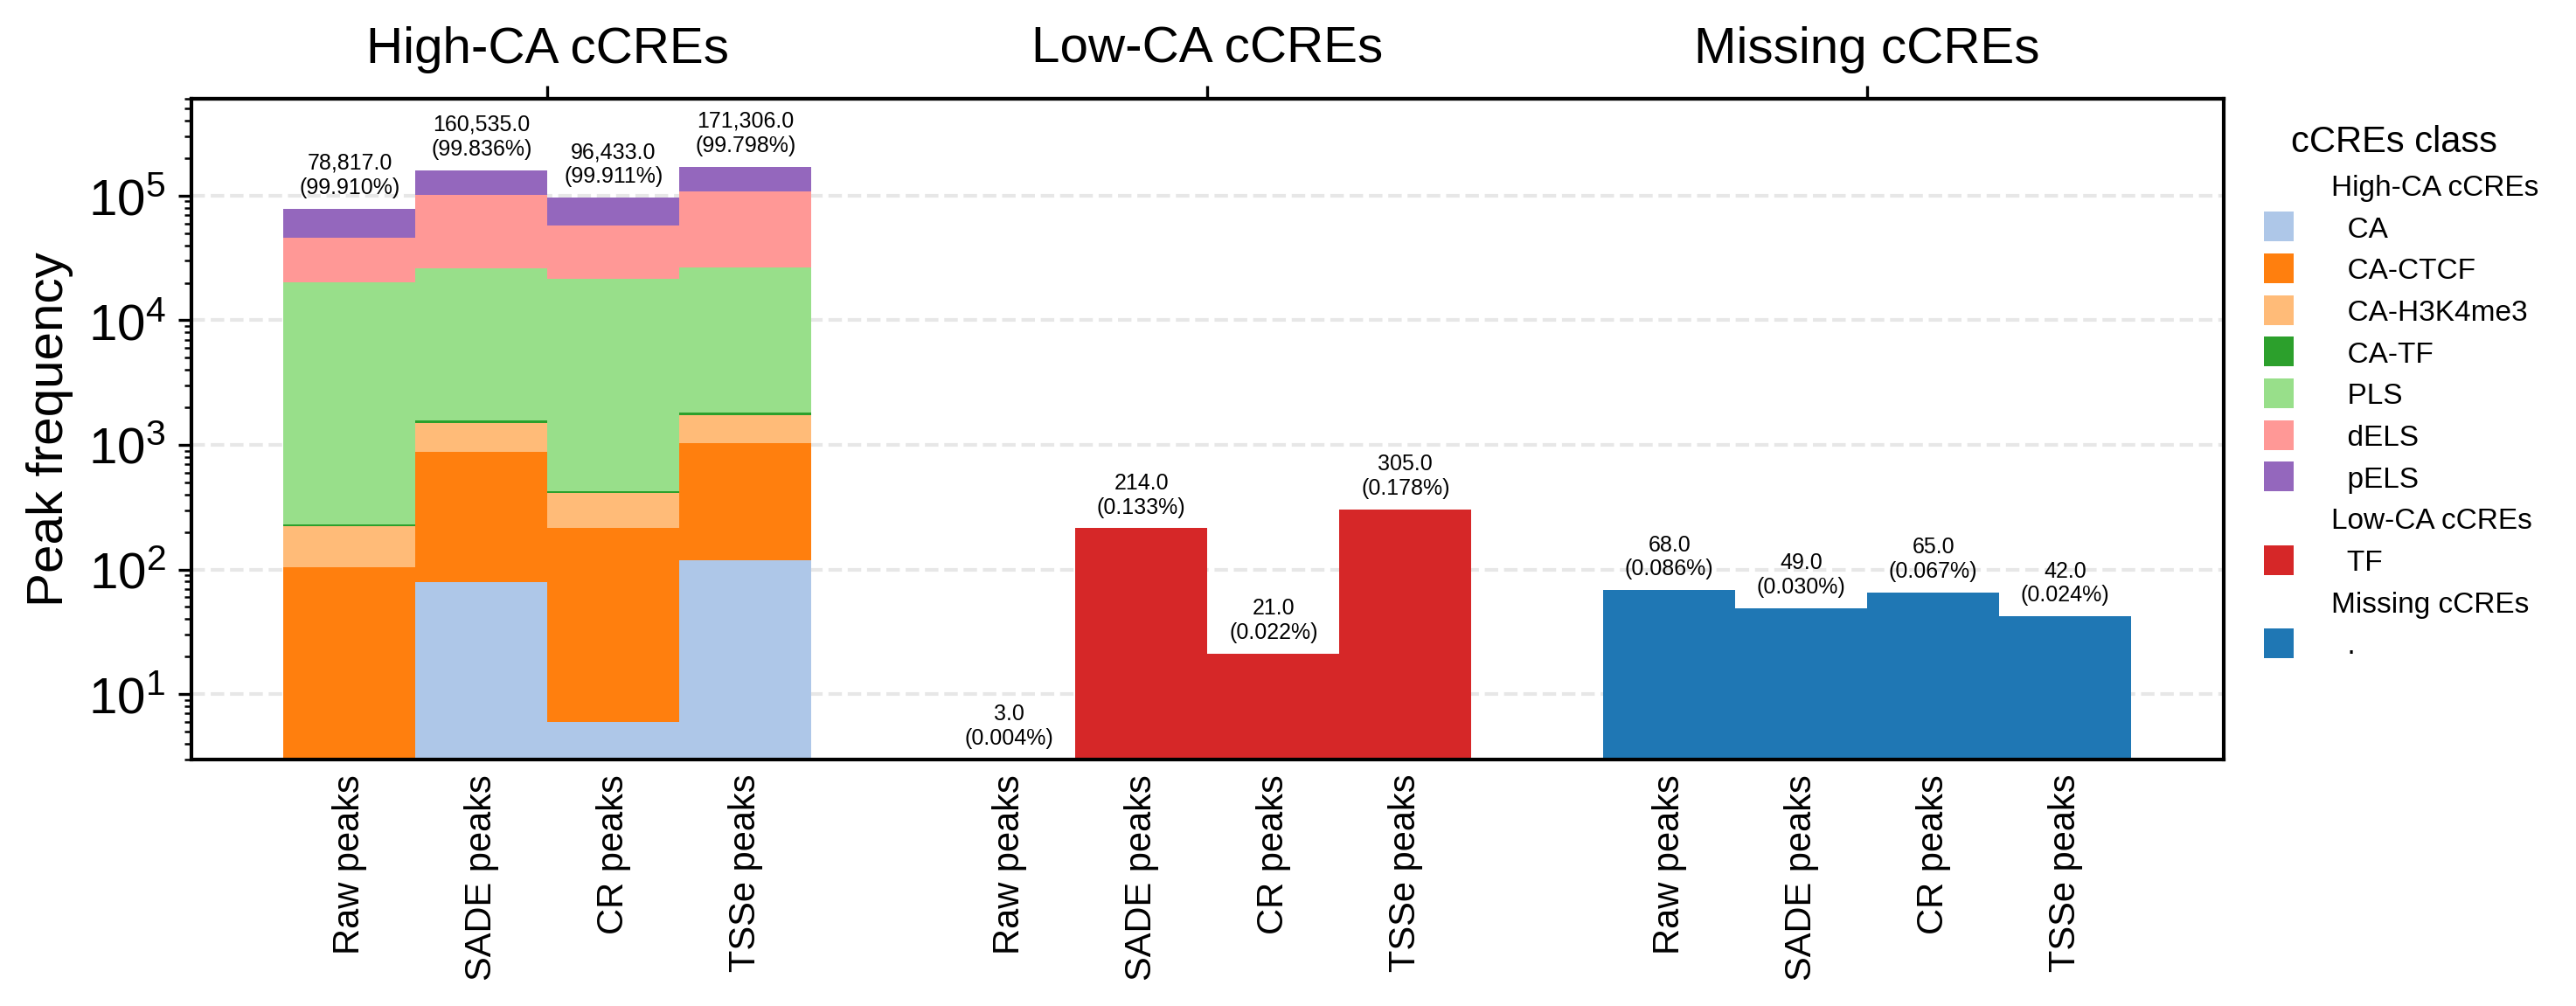

In [104]:
CA_level_color_map = {'High-CA cCREs': 'blue', 'Low-CA cCREs': 'orange', 'Missing cCREs': 'grey'}
CA_level_index_map = {'High-CA cCREs': 0, 'Low-CA cCREs': 1, 'Missing cCREs': 2}
CA_regions_level = {'dELS': 'High-CA cCREs', 'pELS': 'High-CA cCREs', 'PLS': 'High-CA cCREs', 'CA-H3K4me3': 'High-CA cCREs',
                "CA-CTCF": 'High-CA cCREs', 'CA-TF': 'High-CA cCREs', 'TF': 'Low-CA cCREs', "CA": 'High-CA cCREs', '.': 'Missing cCREs'}


datasets = [raw_peaks_cCREs, SADE_vs_raw_cCREs, CR_vs_raw_cCREs, TSSe_vs_raw_cCREs]
dataset_labels = ['Raw peaks', 'SADE peaks', 'CR peaks', 'TSSe peaks']
ca_levels = ['High-CA cCREs', 'Low-CA cCREs', 'Missing cCREs']
classes = sorted(set(
    str(c) for d in datasets
    for c in d['whole_peak_set']['cCREs_class'].dropna().unique()
))
colors = dict(zip(classes, plt.cm.tab20.colors))

width = 0.2
offsets = width * np.array([-1.5, -0.5, 0.5, 1.5])
fig, ax = plt.subplots(figsize=(10, 4))

for d, name, offset in zip(datasets, dataset_labels, offsets):
    df = d['whole_peak_set'].dropna(subset=['cCREs_class']).copy()
    df['CA_level'] = df['cCREs_class'].map(CA_regions_level)
    x = np.array([CA_level_index_map[level] for level in ca_levels]) + offset
    bottom = np.zeros(len(ca_levels))

    for cls in classes:
        counts = np.array([
            ((df['CA_level'] == level) & (df['cCREs_class'] == cls)).sum()
            for level in ca_levels
        ])
        ax.bar(x, counts, width, bottom=bottom, color=colors[cls],
               label=cls if name == dataset_labels[0] else None)
        bottom += counts

    for xi, total in zip(x, bottom):
        pct = 100 * total / len(df) if len(df) else 0
        ax.annotate(f'{total:,}\n({pct:.3f}%)', (xi, total),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=6)

positions = [CA_level_index_map[level] for level in ca_levels]
ax.set_xticks(positions)
ax.tick_params(axis='x', bottom=False, labelbottom=False)
top = ax.secondary_xaxis('top')
top.set_xticks(positions)
top.set_xticklabels(ca_levels)

for offset, name in zip(offsets, dataset_labels):
    for level in ca_levels:
        ax.annotate(name, (CA_level_index_map[level] + offset, 0),
                    xycoords=('data', 'axes fraction'), xytext=(0, -4),
                    textcoords='offset points', ha='center', va='top',
                    rotation=90, fontsize=10, annotation_clip=False)

ax.set_yscale('log')
ax.set_ylim(ax.get_ylim()[0], ax.get_ylim()[1] * 2)
ax.set_ylabel('Peak frequency')
# ax.legend(title='cCREs_class', bbox_to_anchor=(1, 1), loc='upper left')
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
fig.subplots_adjust(bottom=0.25)


from matplotlib.lines import Line2D
handles = []
for level in CA_level_color_map:

    handles.append(Line2D([], [], linestyle="none", label=level))
    # Classes in this section
    for cls in classes:
        if CA_regions_level.get(cls) == level:
            handles.append(
                Line2D([], [], linestyle="none", label=f"  {cls}",
                    marker="s", markersize=8,
                    markerfacecolor=colors[cls],
                    markeredgecolor="none",
                )
            )

legend = ax.legend(
    handles=handles,
    title="cCREs class",
    frameon=False,
    loc='upper left',
    bbox_to_anchor=(1.0, 1 ),
    ncol=1,
    fontsize=8,
    title_fontsize=10
)

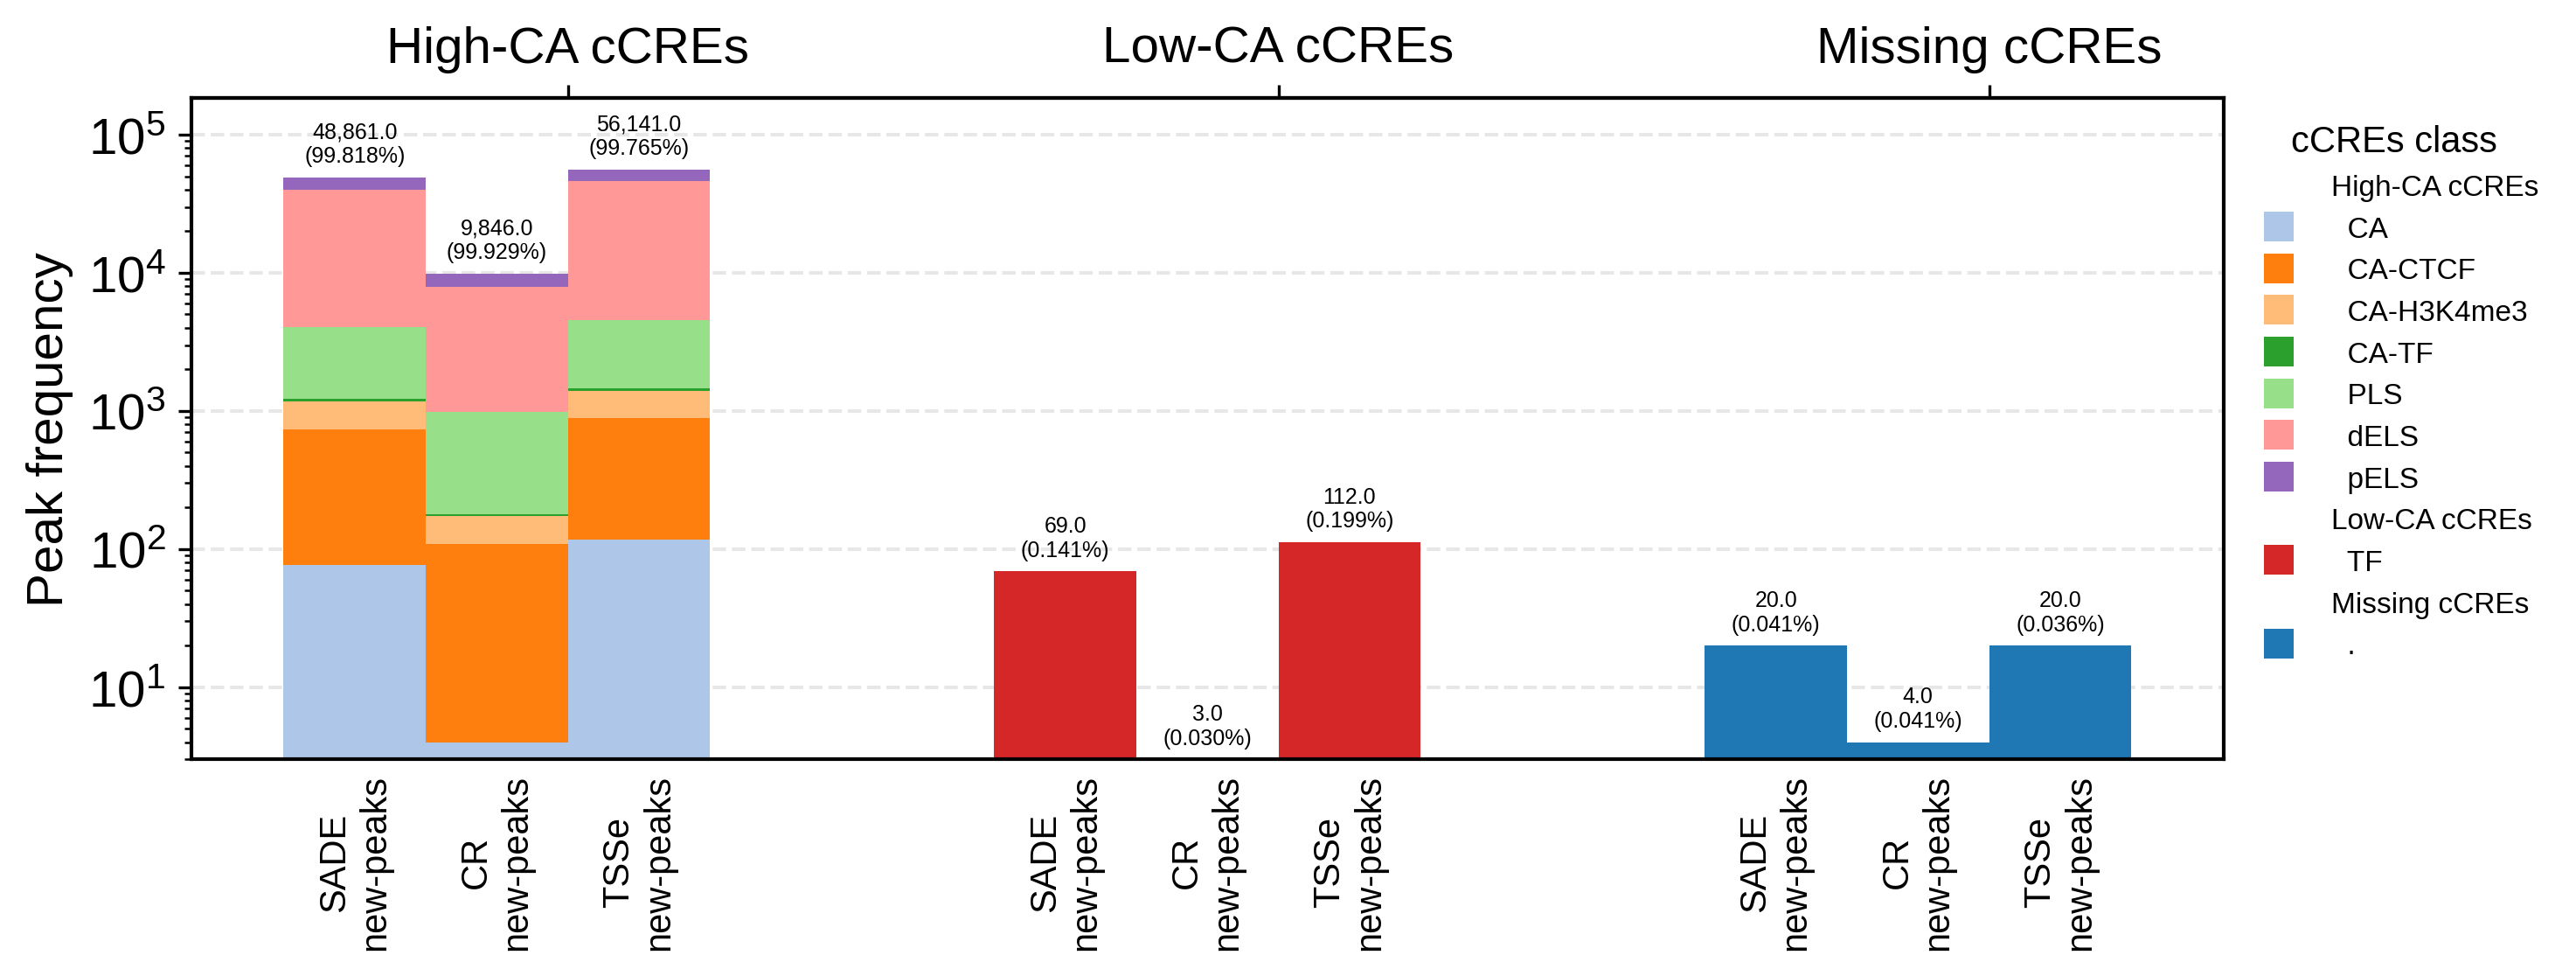

In [107]:
CA_level_color_map = {'High-CA cCREs': 'blue', 'Low-CA cCREs': 'orange', 'Missing cCREs': 'grey'}
CA_level_index_map = {'High-CA cCREs': 0, 'Low-CA cCREs': 1, 'Missing cCREs': 2}
CA_regions_level = {'dELS': 'High-CA cCREs', 'pELS': 'High-CA cCREs', 'PLS': 'High-CA cCREs', 'CA-H3K4me3': 'High-CA cCREs',
                "CA-CTCF": 'High-CA cCREs', 'CA-TF': 'High-CA cCREs', 'TF': 'Low-CA cCREs', "CA": 'High-CA cCREs', '.': 'Missing cCREs'}


datasets = [ SADE_vs_raw_cCREs, CR_vs_raw_cCREs, TSSe_vs_raw_cCREs]
dataset_labels = [ 'SADE\nnew-peaks', 'CR\nnew-peaks', 'TSSe\nnew-peaks']
ca_levels = ['High-CA cCREs', 'Low-CA cCREs', 'Missing cCREs']
classes = sorted(set(
    str(c) for d in datasets
    for c in d['newly_discovered_peaks']['cCREs_class'].dropna().unique()
))
colors = dict(zip(classes, plt.cm.tab20.colors))

width = 0.2
offsets = width * np.array([-1.5, -0.5, 0.5, 1.5])
fig, ax = plt.subplots(figsize=(10, 4))

for d, name, offset in zip(datasets, dataset_labels, offsets):
    df = d['newly_discovered_peaks'].dropna(subset=['cCREs_class']).copy()
    df['CA_level'] = df['cCREs_class'].map(CA_regions_level)
    x = np.array([CA_level_index_map[level] for level in ca_levels]) + offset
    bottom = np.zeros(len(ca_levels))

    for cls in classes:
        counts = np.array([
            ((df['CA_level'] == level) & (df['cCREs_class'] == cls)).sum()
            for level in ca_levels
        ])
        ax.bar(x, counts, width, bottom=bottom, color=colors[cls],
               label=cls if name == dataset_labels[0] else None)
        bottom += counts

    for xi, total in zip(x, bottom):
        pct = 100 * total / len(df) if len(df) else 0
        ax.annotate(f'{total:,}\n({pct:.3f}%)', (xi, total),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=6)

positions = [CA_level_index_map[level] for level in ca_levels]
ax.set_xticks(positions)
ax.tick_params(axis='x', bottom=False, labelbottom=False)
top = ax.secondary_xaxis('top')
top.set_xticks(positions)
top.set_xticklabels(ca_levels)

for offset, name in zip(offsets, dataset_labels):
    for level in ca_levels:
        ax.annotate(name, (CA_level_index_map[level] + offset, 0),
                    xycoords=('data', 'axes fraction'), xytext=(0, -4),
                    textcoords='offset points', ha='center', va='top',
                    rotation=90, fontsize=10, annotation_clip=False)

ax.set_yscale('log')
ax.set_ylim(ax.get_ylim()[0], ax.get_ylim()[1] * 2)
ax.set_ylabel('Peak frequency')
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
fig.subplots_adjust(bottom=0.25)


from matplotlib.lines import Line2D
handles = []
for level in CA_level_color_map:

    handles.append(Line2D([], [], linestyle="none", label=level))
    # Classes in this section
    for cls in classes:
        if CA_regions_level.get(cls) == level:
            handles.append(
                Line2D([], [], linestyle="none", label=f"  {cls}",
                    marker="s", markersize=8,
                    markerfacecolor=colors[cls],
                    markeredgecolor="none",
                )
            )

legend = ax.legend(
    handles=handles,
    title="cCREs class",
    frameon=False,
    loc='upper left',
    bbox_to_anchor=(1.0, 1 ),
    ncol=1,
    fontsize=8,
    title_fontsize=10
)

[Text(0, 0, 'High-CA cCREs'),
 Text(1, 0, 'Low-CA cCREs'),
 Text(2, 0, 'No cCREs')]

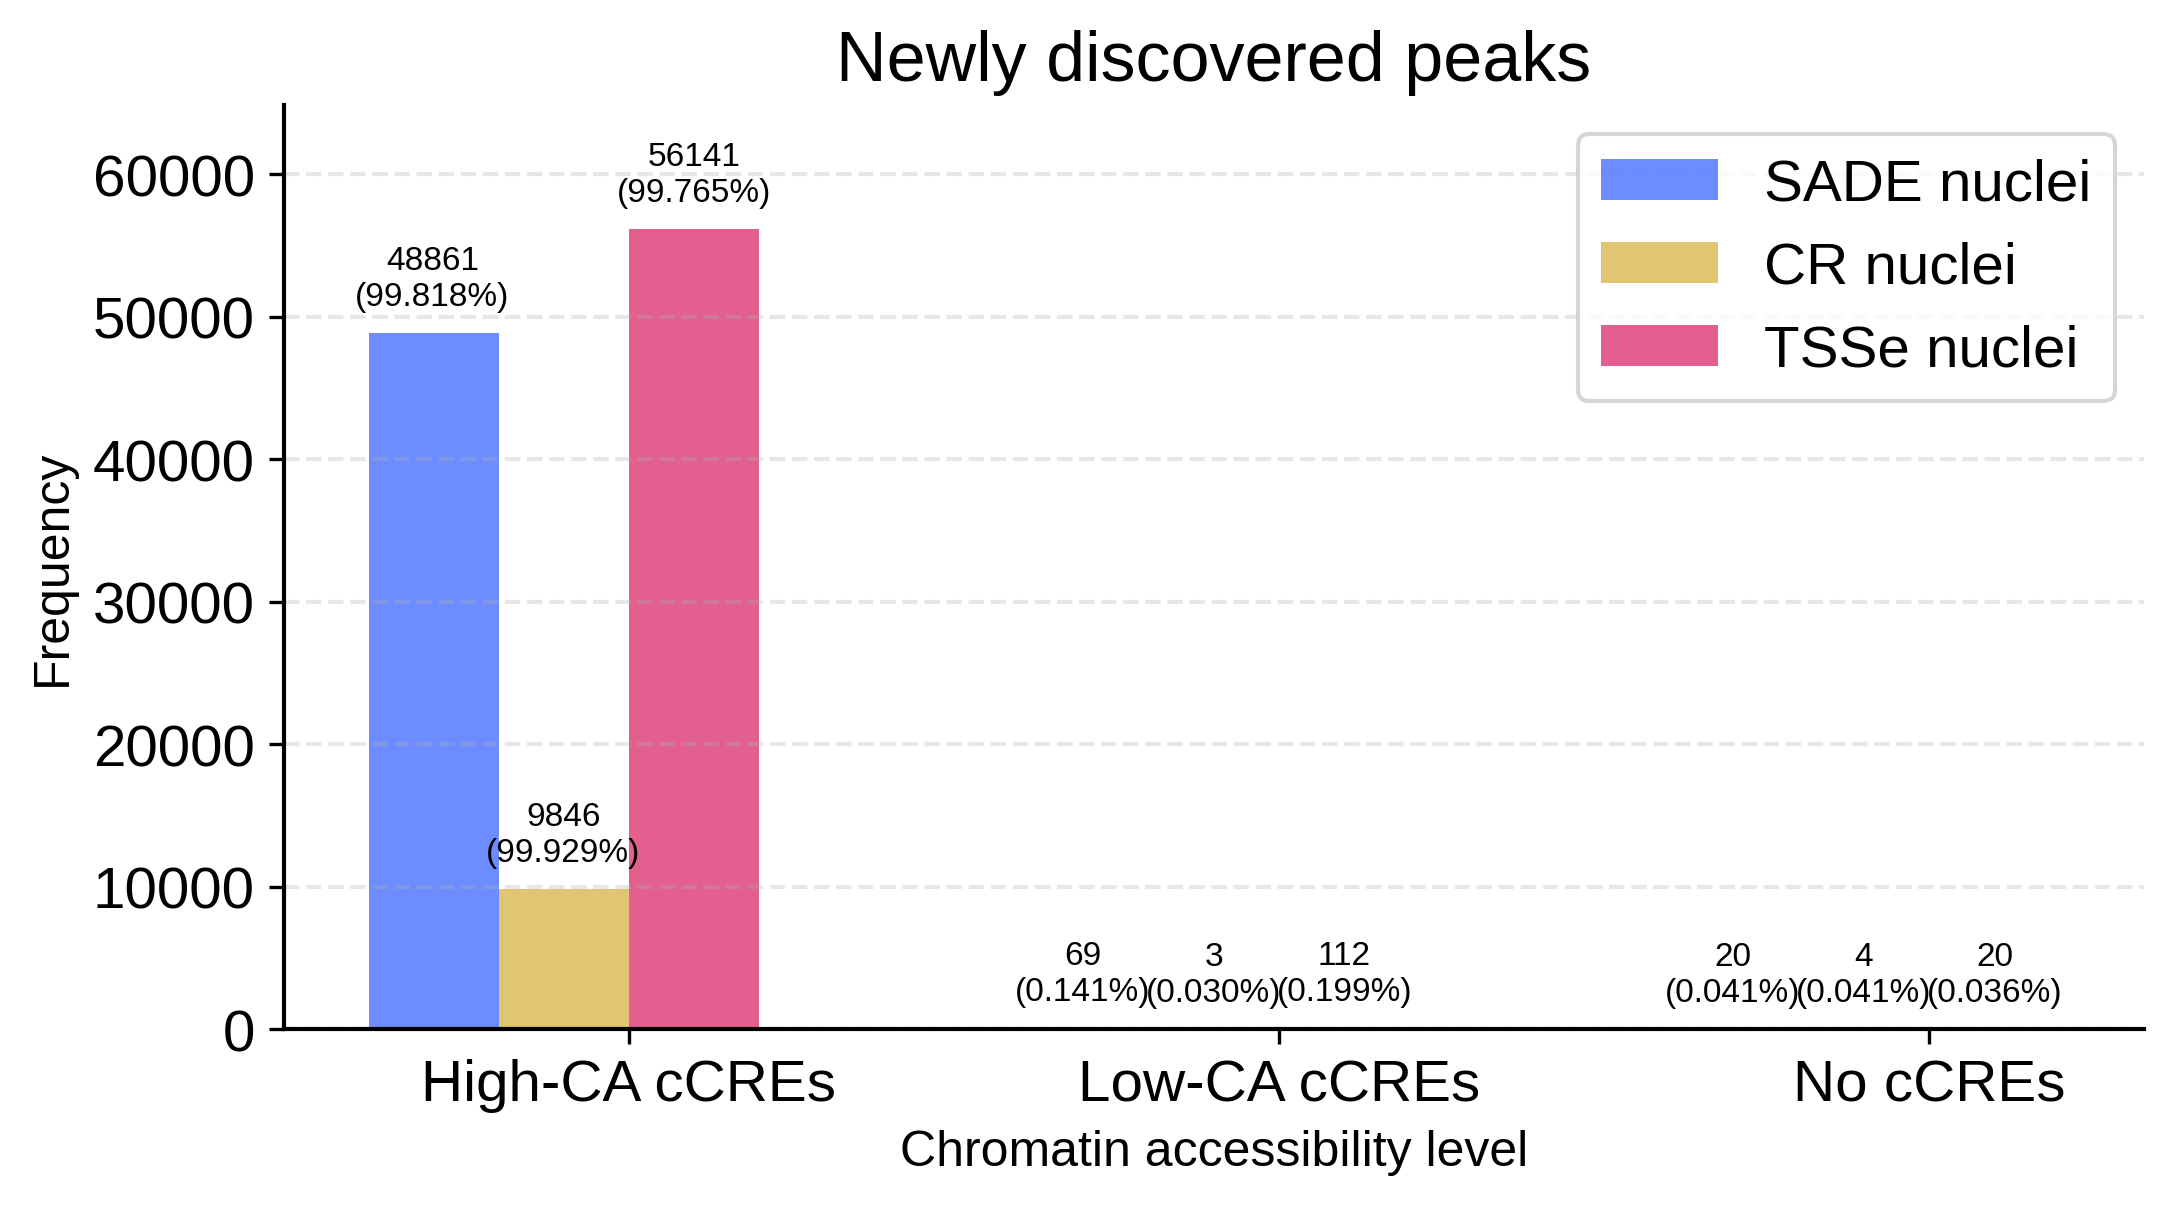

In [11]:
CA_level_color_map = {'High-CA cCREs': 'blue', 'Low-CA cCREs': 'orange', 'No cCREs': 'grey'}
CA_level_index_map = {'High-CA cCREs': 0, 'Low-CA cCREs': 1, 'No cCREs': 2}
CA_regions_level = {'dELS': 'High-CA cCREs', 'pELS': 'High-CA cCREs', 'PLS': 'High-CA cCREs', 'CA-H3K4me3': 'High-CA cCREs',
                "CA-CTCF": 'High-CA cCREs', 'CA-TF': 'High-CA cCREs', 'TF': 'Low-CA cCREs', "CA": 'High-CA cCREs', '.': 'No cCREs'}

width = 0.2  # the width of the bars
fig, ax = plt.subplots( nrows=1, ncols=1, figsize=(8,4))

for d, c, poffset, l in zip([ SADE_vs_raw_cCREs, CR_vs_raw_cCREs,   TSSe_vs_raw_cCREs], [ '#2E5BFF', "#D4AF37",  '#D81B60', ],
                    width*np.array([-1.5, -0.5, 0.5,]),
                    [ 'SADE nuclei','CR nuclei', 'TSSe nuclei']):
    freq_df = d['newly_discovered_peaks'].dropna(subset=['cCREs_class'], inplace=False
                                         )['cCREs_class'].map(CA_regions_level).value_counts()
    percent = freq_df / freq_df.sum() * 100
    x_positions = [CA_level_index_map[idx] + poffset for idx in freq_df.index]
    bars = ax.bar(x_positions, freq_df.values, width=width, alpha=0.7, color=c, label=f'{l}')
    for bar, class_name in zip(bars, freq_df.index):
        ax.annotate(
            f'{freq_df[class_name]}\n({percent[class_name]:.3f}%)',
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0 +  poffset, 5 ),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=8,
            rotation=0
        )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_xlabel('Chromatin accessibility level', fontsize=12) 
ax.legend(loc='upper right', ncols=1, bbox_to_anchor=(1, 1))
ax.set_title('Newly discovered peaks')


ticks = sorted(CA_level_index_map.values())
labels = sorted(CA_level_index_map, key=CA_level_index_map.get)
ax.set_xticks(ticks)
ax.set_xticklabels(labels, rotation=0, ha='center')

[Text(0, 0, 'dELS'),
 Text(1, 0, 'pELS'),
 Text(2, 0, 'PLS'),
 Text(3, 0, 'CA-H3K4me3'),
 Text(4, 0, 'CA-CTCF'),
 Text(5, 0, 'CA-TF'),
 Text(6, 0, 'TF'),
 Text(7, 0, 'CA'),
 Text(8, 0, '.')]

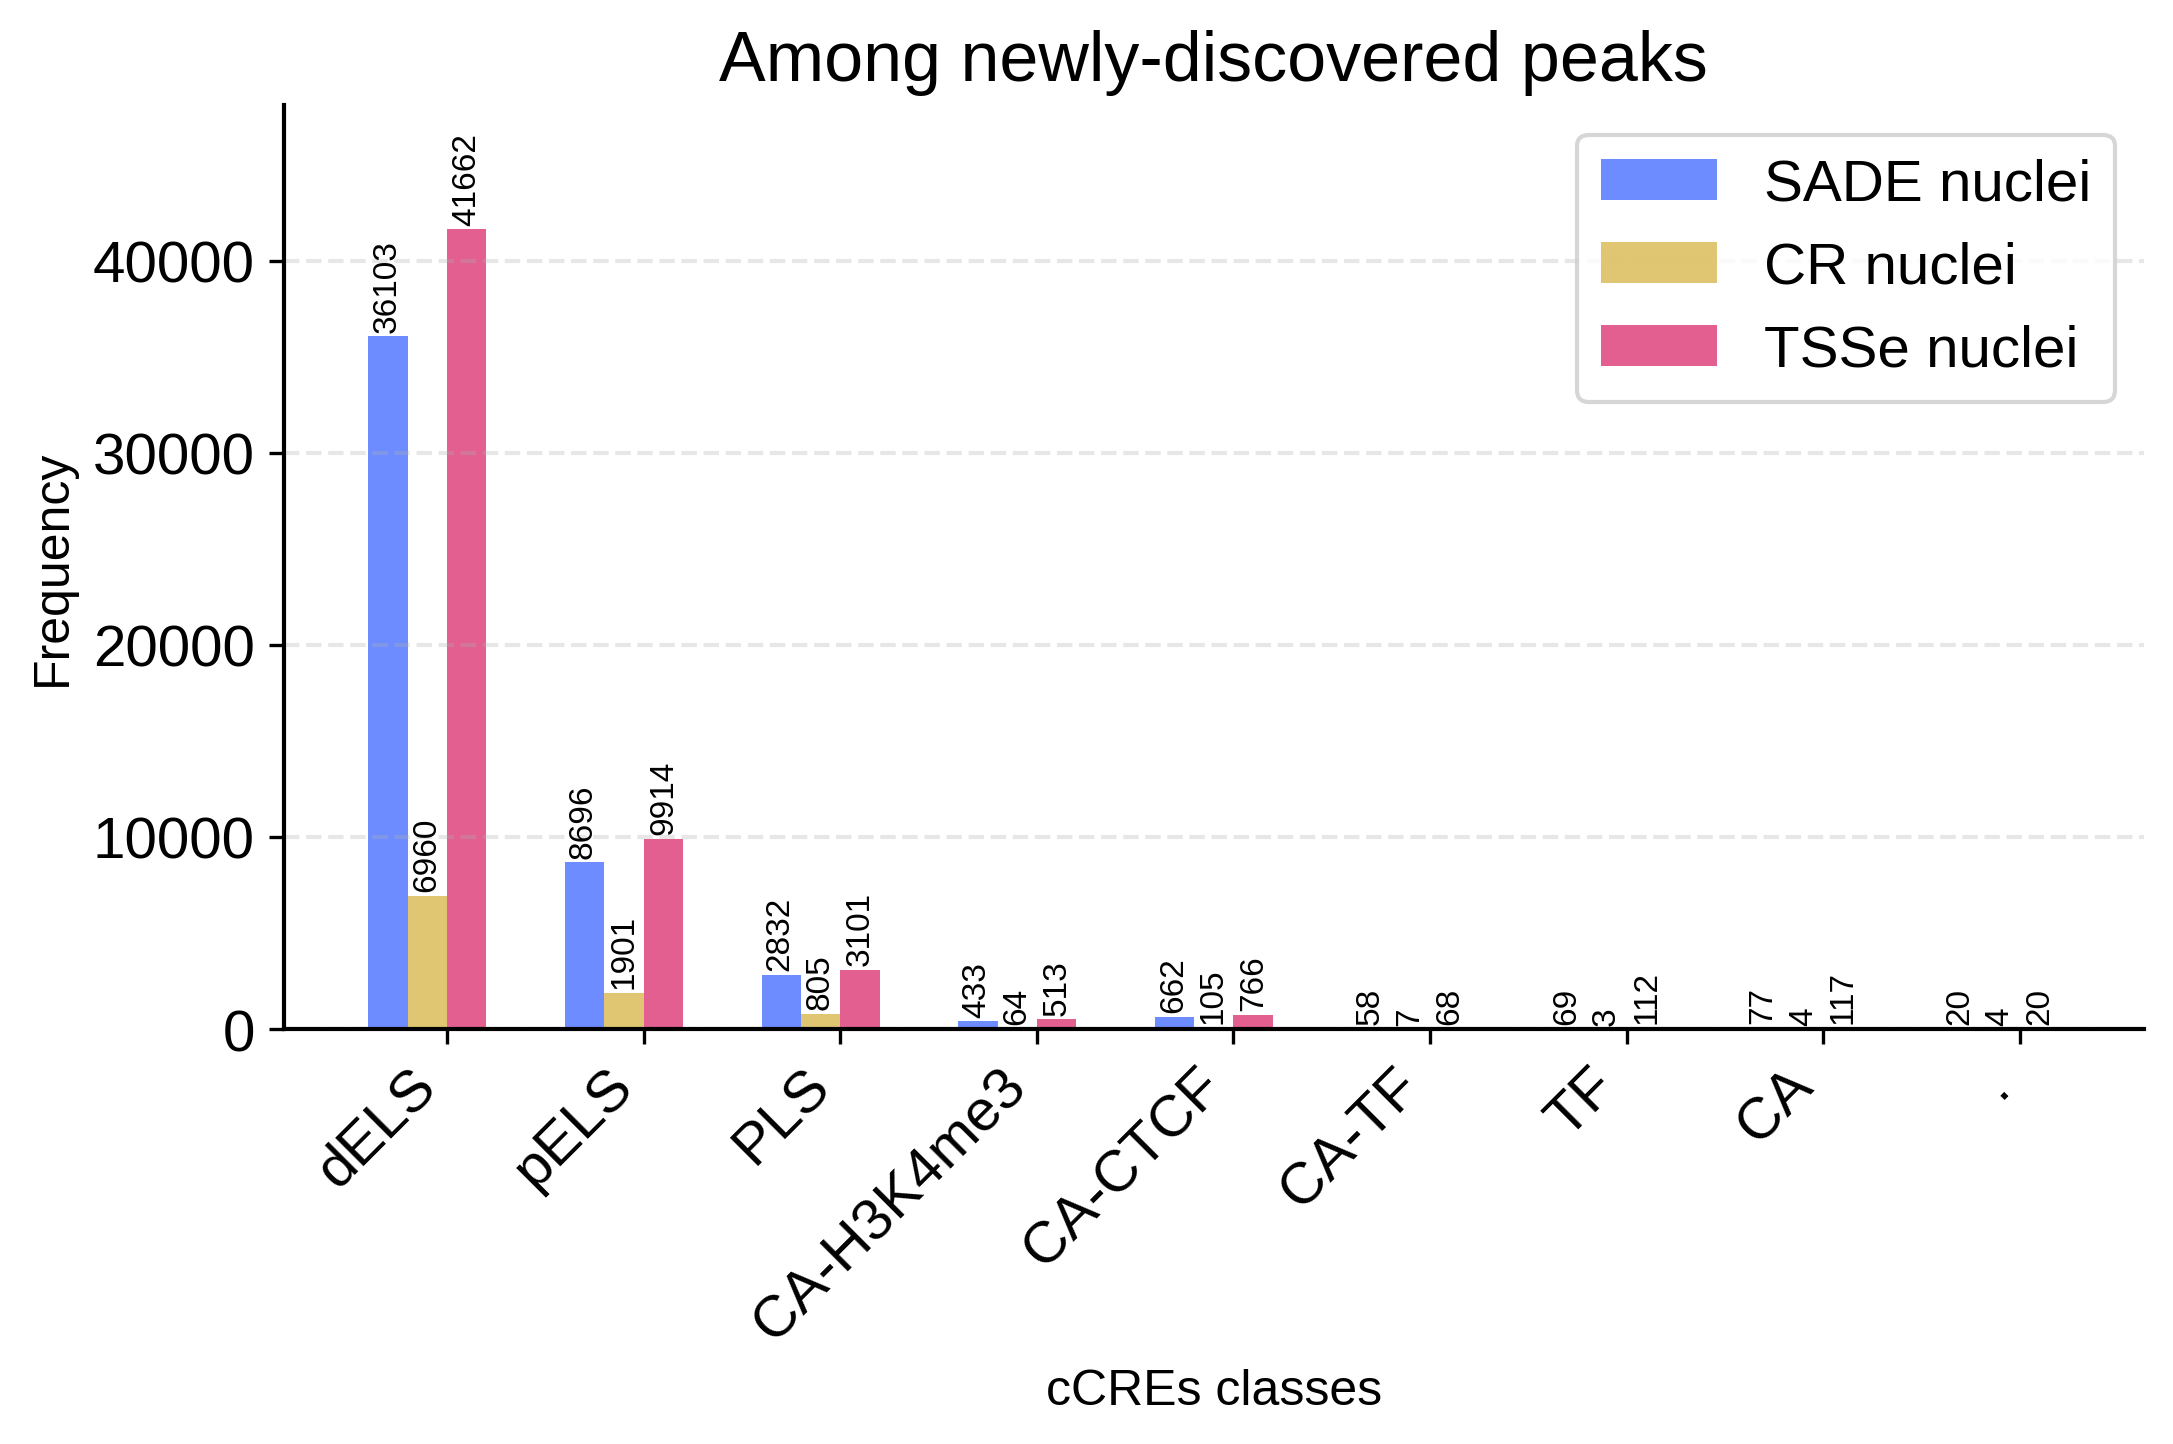

In [12]:
color_map = {'dELS': 'blue', 'pELS': 'orange', 'PLS': 'skyblue', 'CA-H3K4me3': 'red',
                "CA-CTCF": 'purple', 'CA-TF': 'brown', 'TF': 'pink', "CA": 'slateblue', '.': 'grey'}
index_map = {'dELS': 0, 'pELS': 1, 'PLS': 2, 'CA-H3K4me3': 3,
                "CA-CTCF": 4, 'CA-TF': 5, 'TF': 6, "CA": 7, '.': 8}

width = 0.2  # the width of the bars
fig, ax = plt.subplots( nrows=1, ncols=1, figsize=(8,4))

for d, c, poffset, l in zip([SADE_vs_raw_cCREs, CR_vs_raw_cCREs, TSSe_vs_raw_cCREs], ['#2E5BFF', "#D4AF37", '#D81B60'],
                    0.2*np.array([-1.5, -0.5, 0.5]),
                    ['SADE nuclei', 'CR nuclei', 'TSSe nuclei']):
    freq_df = d['newly_discovered_peaks'].dropna(subset=['cCREs_class'], inplace=False
                                                 )['cCREs_class'].value_counts()
    x_positions = [index_map[idx] + poffset for idx in freq_df.index]
    bars = ax.bar(x_positions, freq_df.values, width=width, alpha=0.7, color=c, label=f'{l}')
    for bar, class_name in zip(bars, freq_df.index):
        ax.annotate(
            f'{freq_df[class_name]}',
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0 +  poffset, 1 ),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=8,
            rotation=90
        )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_xlabel('cCREs classes', fontsize=12) 
ax.legend(loc='upper right', ncols=1, bbox_to_anchor=(1, 1))
ax.set_title('Among newly-discovered peaks')


ticks = sorted(index_map.values())
labels = sorted(index_map, key=index_map.get)
ax.set_xticks(ticks)
ax.set_xticklabels(labels, rotation=45, ha='right')

[Text(0, 0, 'dELS'),
 Text(1, 0, 'pELS'),
 Text(2, 0, 'PLS'),
 Text(3, 0, 'CA-H3K4me3'),
 Text(4, 0, 'CA-CTCF'),
 Text(5, 0, 'CA-TF'),
 Text(6, 0, 'TF'),
 Text(7, 0, 'CA'),
 Text(8, 0, '.')]

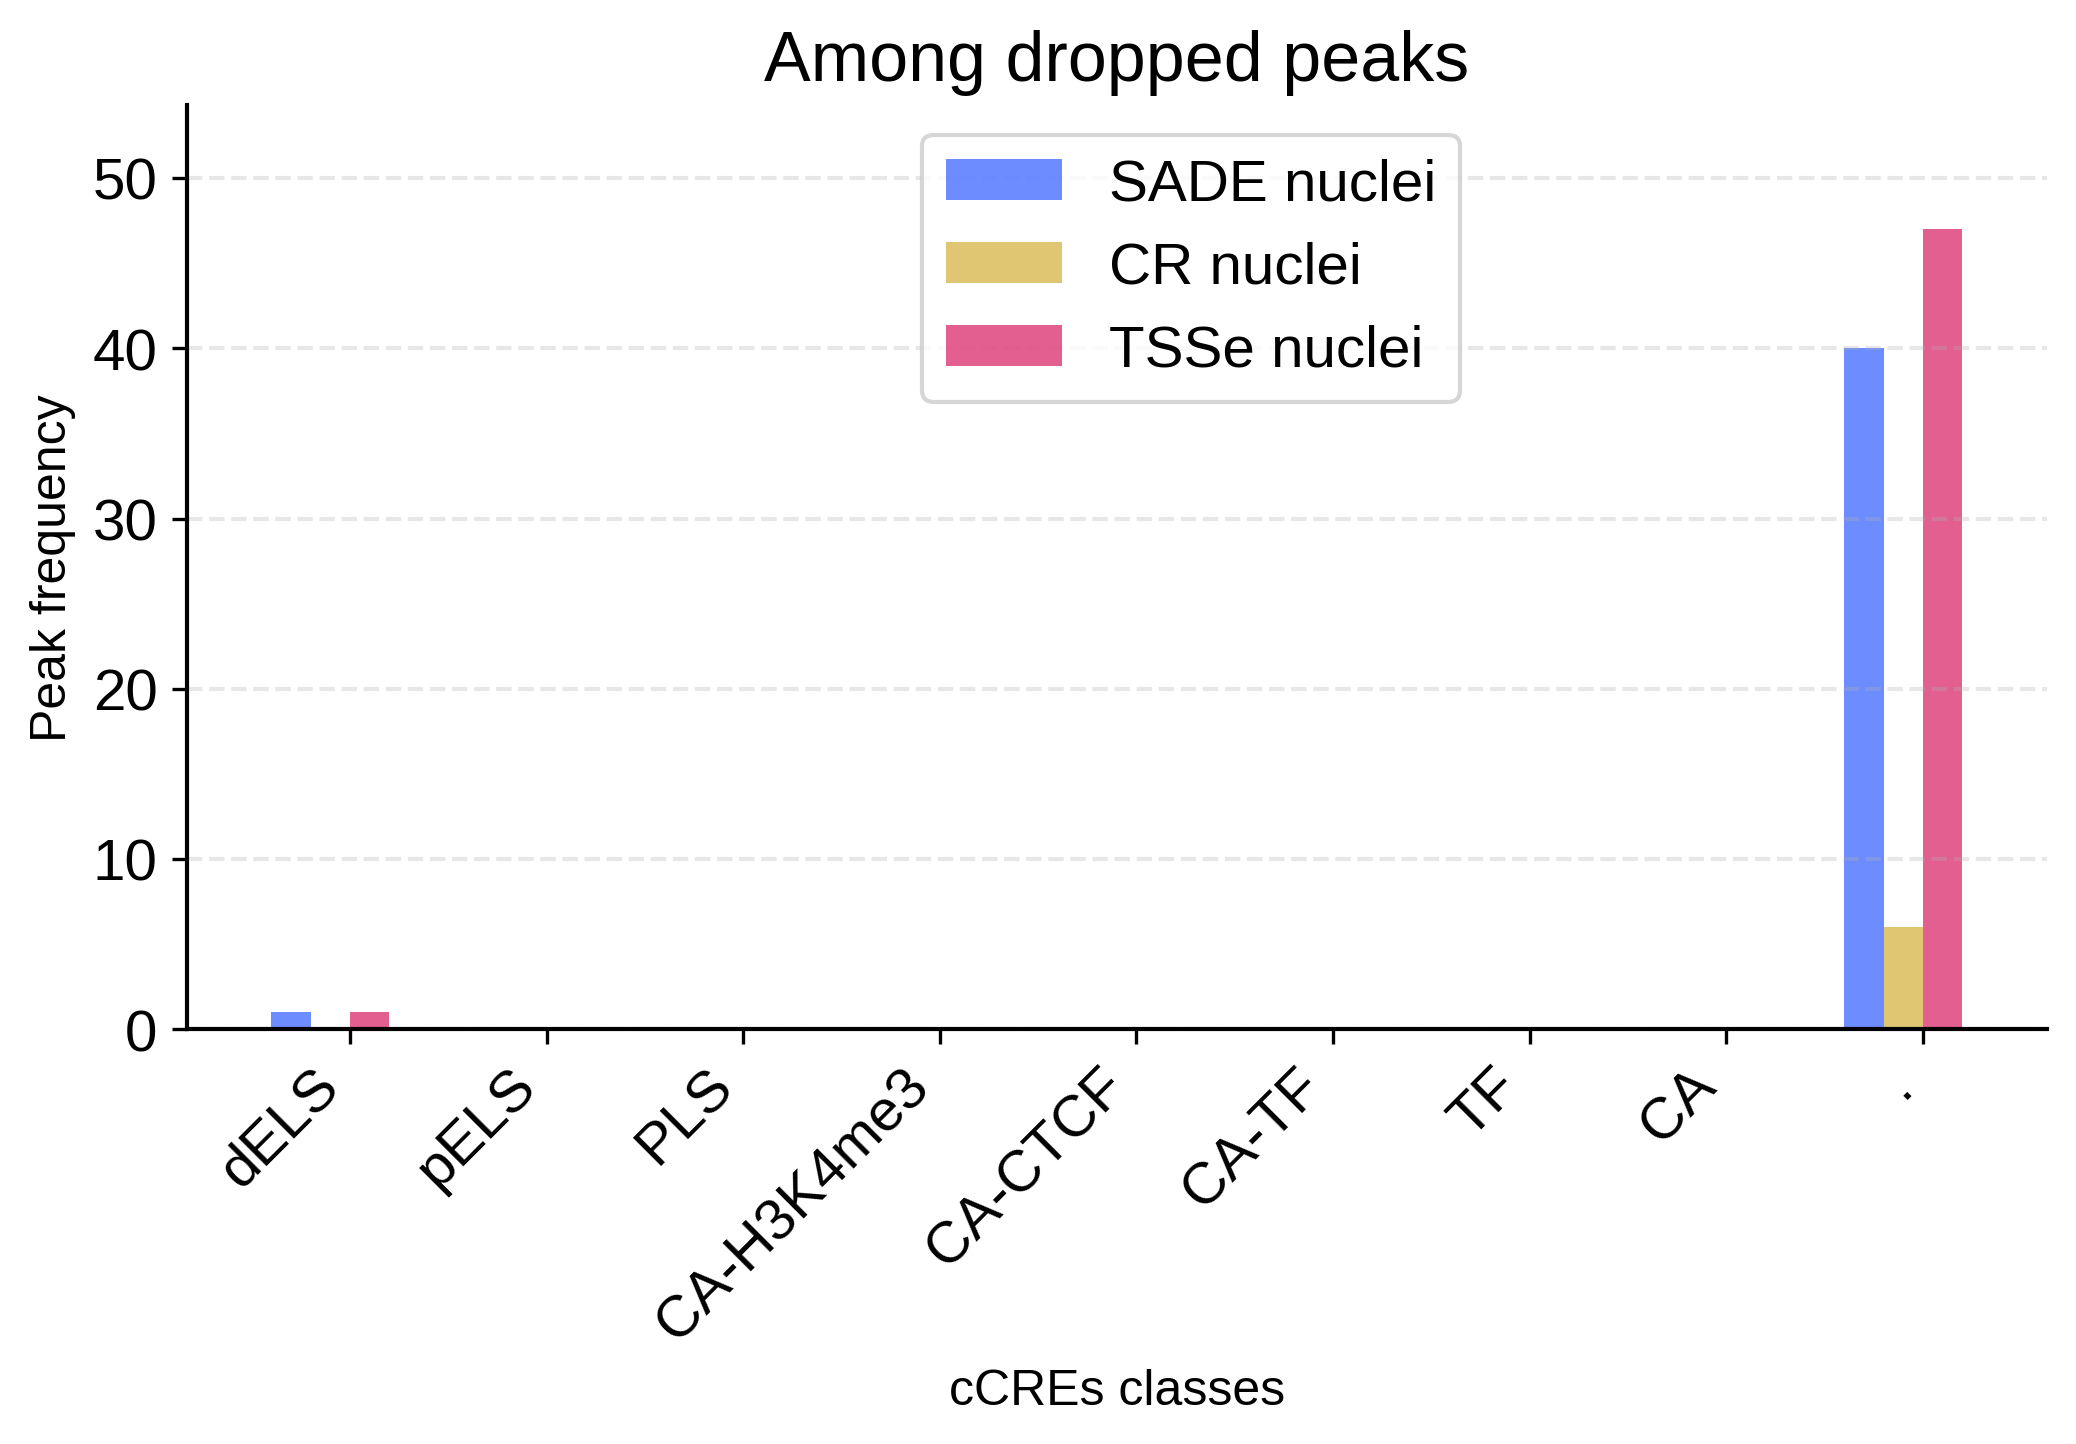

In [13]:
color_map = {'dELS': 'blue', 'pELS': 'orange', 'PLS': 'skyblue', 'CA-H3K4me3': 'red',
                "CA-CTCF": 'purple', 'CA-TF': 'brown', 'TF': 'pink', "CA": 'slateblue', '.': 'grey'}
index_map = {'dELS': 0, 'pELS': 1, 'PLS': 2, 'CA-H3K4me3': 3,
                "CA-CTCF": 4, 'CA-TF': 5, 'TF': 6, "CA": 7, '.': 8}

width = 0.2  # the width of the bars
fig, ax = plt.subplots( nrows=1, ncols=1, figsize=(8,4))

for d, c, poffset, l in zip([SADE_vs_raw_cCREs, CR_vs_raw_cCREs, TSSe_vs_raw_cCREs], ['#2E5BFF', "#D4AF37", '#D81B60'],
                    width*np.array([-1.5, -0.5, 0.5]),
                    ['SADE nuclei', 'CR nuclei', 'TSSe nuclei', ]):
    freq_df = d['dropped_peaks'].dropna(subset=['cCREs_class'], inplace=False
                                                 )['cCREs_class'].value_counts()
    x_positions = [index_map[idx] + poffset for idx in freq_df.index]
    bars = ax.bar(x_positions, freq_df.values, width=width, alpha=0.7, color=c, label=f'{l}')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_ylabel('Peak frequency', fontsize=12)
ax.set_xlabel('cCREs classes', fontsize=12) 
ax.legend(loc='upper right', ncols=1, bbox_to_anchor=(0.7, 1))
ax.set_title('Among dropped peaks')


ticks = sorted(index_map.values())
labels = sorted(index_map, key=index_map.get)
ax.set_xticks(ticks)
ax.set_xticklabels(labels, rotation=45, ha='right')

[Text(0, 0, 'dELS'),
 Text(1, 0, 'pELS'),
 Text(2, 0, 'PLS'),
 Text(3, 0, 'CA-H3K4me3'),
 Text(4, 0, 'CA-CTCF'),
 Text(5, 0, 'CA-TF'),
 Text(6, 0, 'TF'),
 Text(7, 0, 'CA'),
 Text(8, 0, '.')]

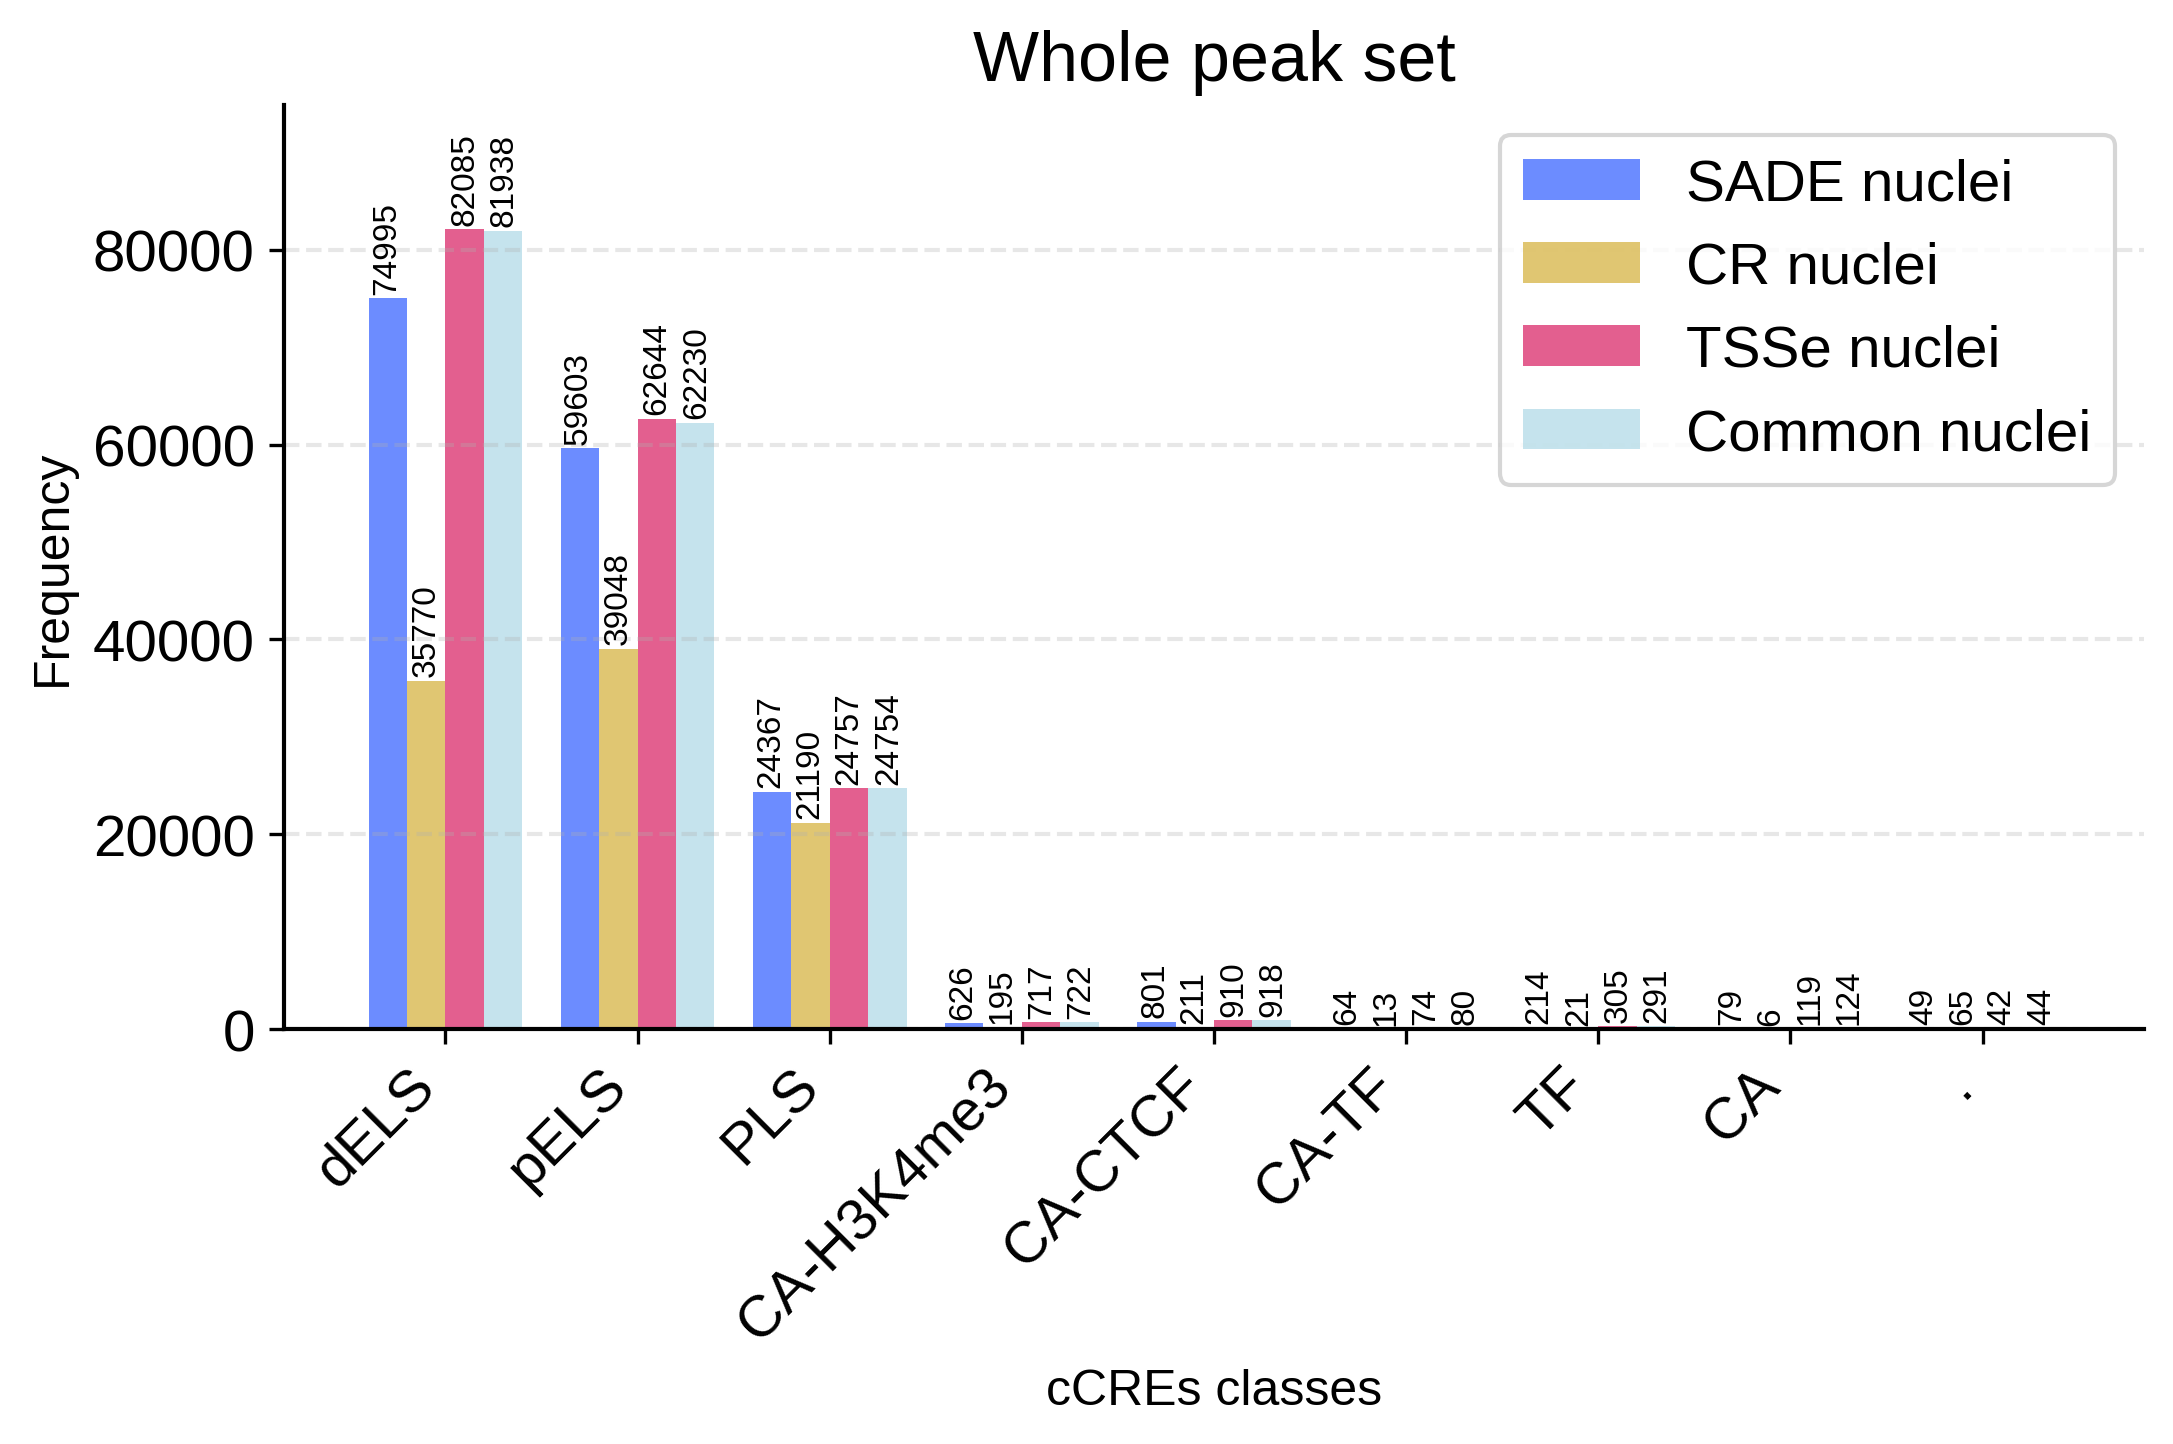

In [14]:
color_map = {'dELS': 'blue', 'pELS': 'orange', 'PLS': 'skyblue', 'CA-H3K4me3': 'red',
                "CA-CTCF": 'purple', 'CA-TF': 'brown', 'TF': 'pink', "CA": 'slateblue', '.': 'grey'}
index_map = {'dELS': 0, 'pELS': 1, 'PLS': 2, 'CA-H3K4me3': 3,
                "CA-CTCF": 4, 'CA-TF': 5, 'TF': 6, "CA": 7, '.': 8}

width = 0.2  # the width of the bars
fig, ax = plt.subplots( nrows=1, ncols=1, figsize=(8,4))

for d, c, poffset, l in zip([SADE_vs_raw_cCREs, CR_vs_raw_cCREs, TSSe_vs_raw_cCREs, common_vs_raw_cCREs], ['#2E5BFF', "#D4AF37", '#D81B60', 'lightblue'],
                    0.2*np.array([-1.5, -0.5, 0.5, 1.5]),
                    ['SADE nuclei', 'CR nuclei', 'TSSe nuclei', 'Common nuclei']):
    freq_df = d['whole_peak_set'].dropna(subset=['cCREs_class'], inplace=False
                                                 )['cCREs_class'].value_counts()
    x_positions = [index_map[idx] + poffset for idx in freq_df.index]
    bars = ax.bar(x_positions, freq_df.values, width=width, alpha=0.7, color=c, label=f'{l}')
    for bar, class_name in zip(bars, freq_df.index):
        ax.annotate(
            f'{freq_df[class_name]}',
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0 +  poffset, 1 ),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=8,
            rotation=90
        )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_xlabel('cCREs classes', fontsize=12) 
ax.legend(loc='upper right', ncols=1, bbox_to_anchor=(1, 1))
ax.set_title('Whole peak set')


ticks = sorted(index_map.values())
labels = sorted(index_map, key=index_map.get)
ax.set_xticks(ticks)
ax.set_xticklabels(labels, rotation=45, ha='right')

-----

[Text(0, 0, 'dELS'),
 Text(1, 0, 'pELS'),
 Text(2, 0, 'PLS'),
 Text(3, 0, 'CA-H3K4me3'),
 Text(4, 0, 'CA-CTCF'),
 Text(5, 0, 'CA-TF'),
 Text(6, 0, 'TF'),
 Text(7, 0, 'CA'),
 Text(8, 0, '.')]

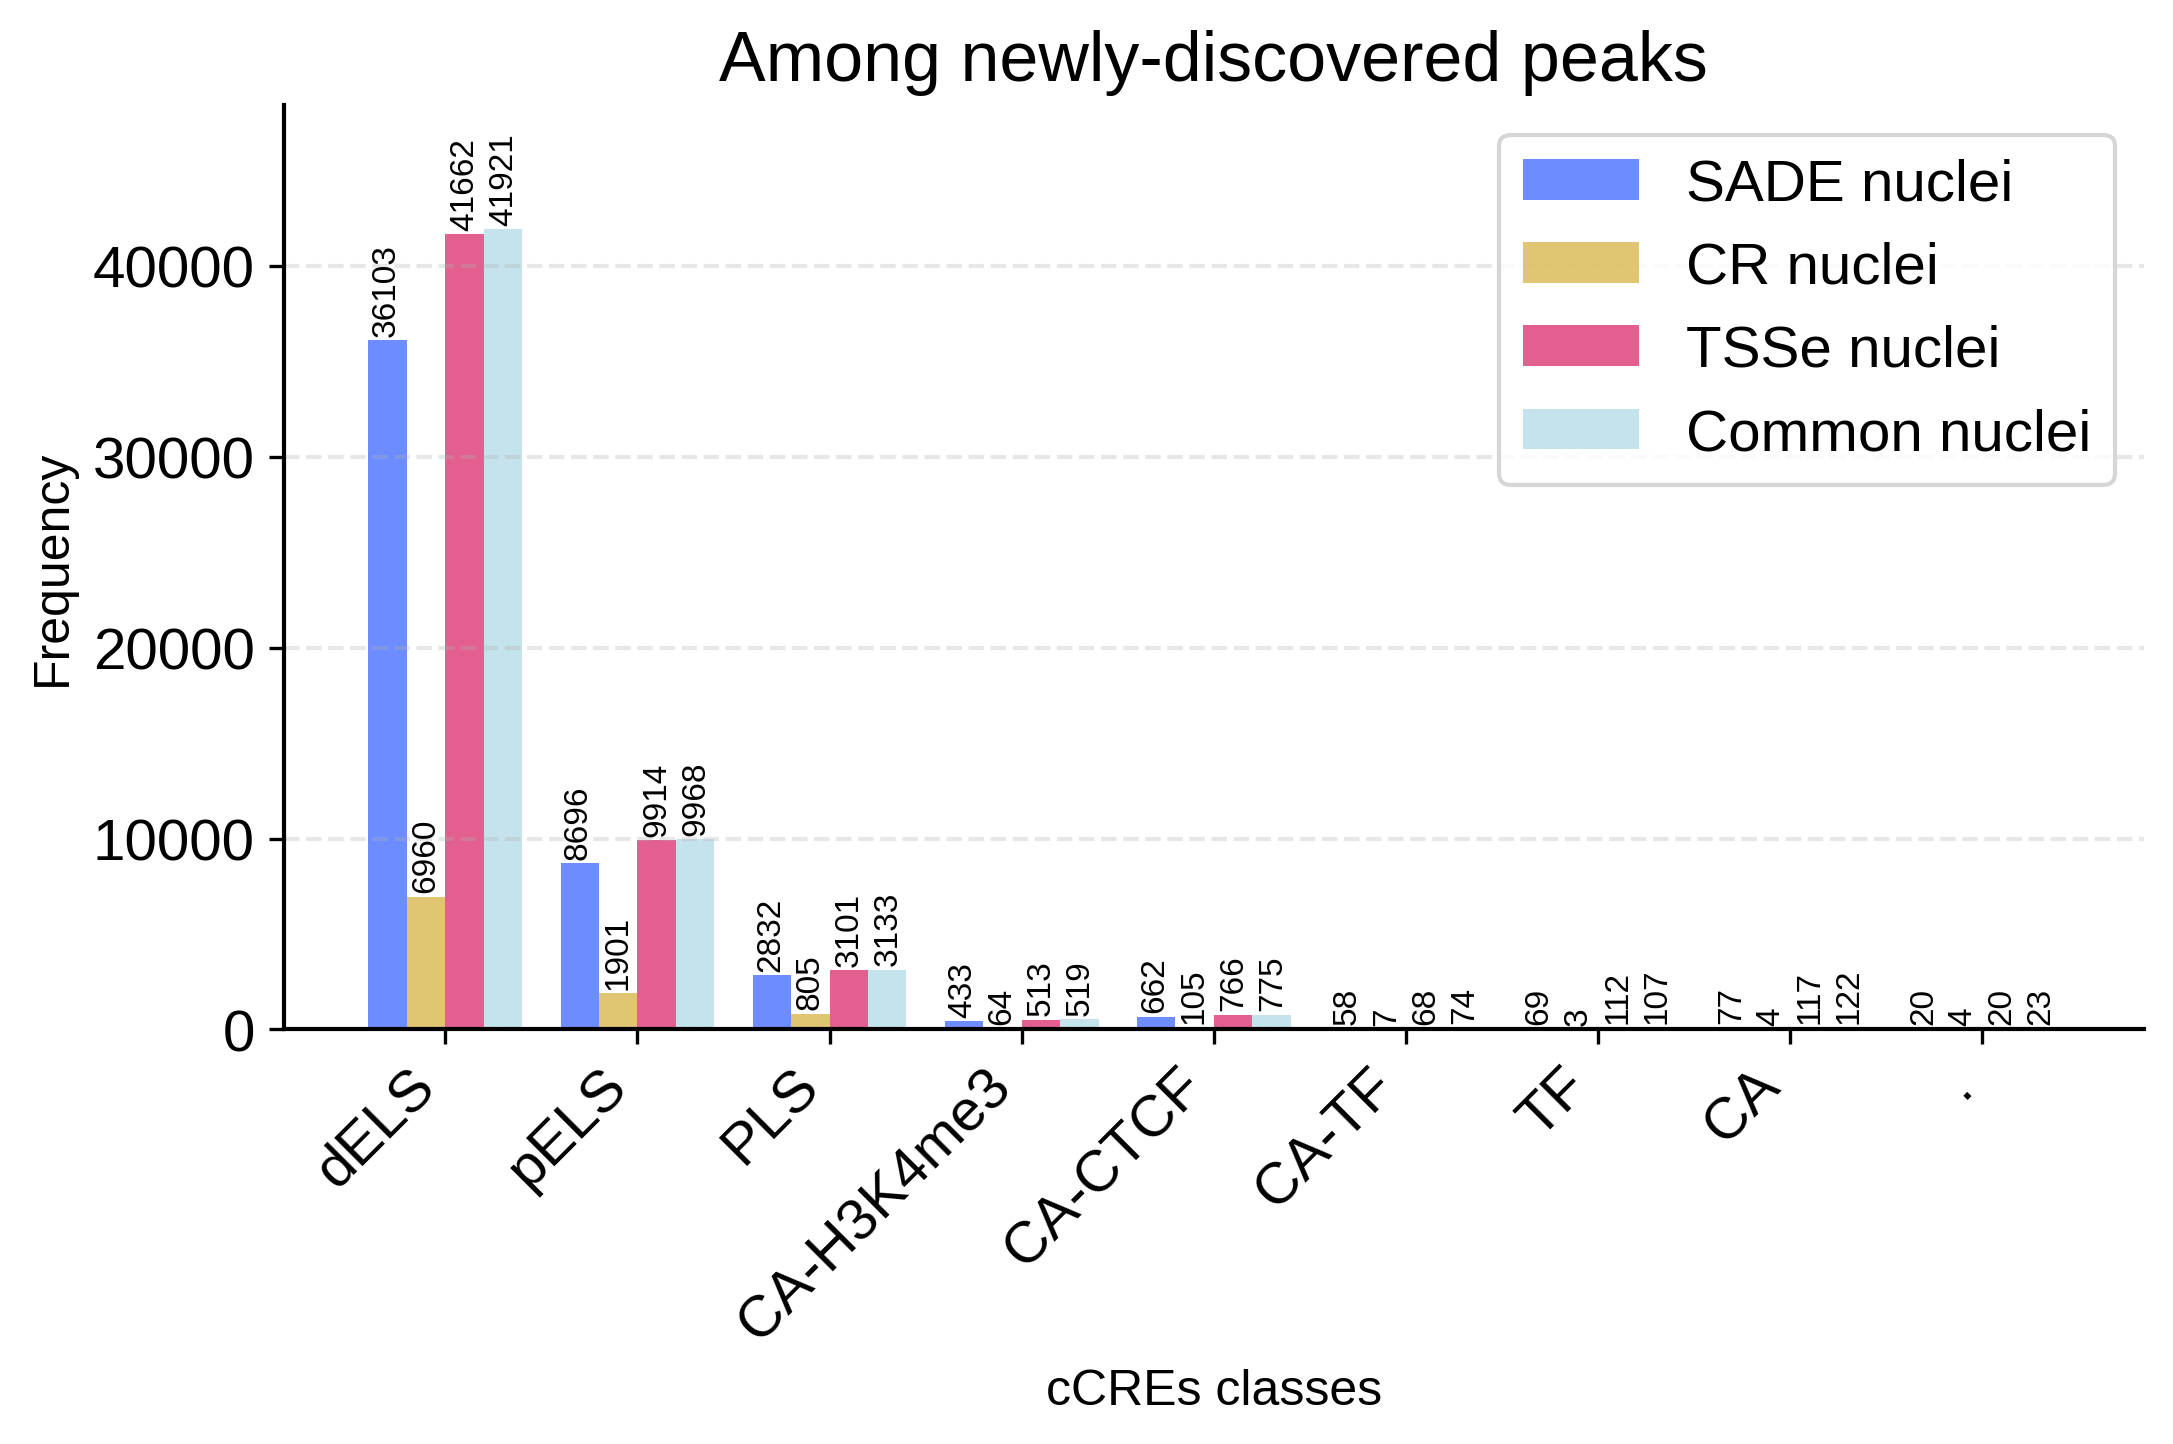

In [15]:
color_map = {'dELS': 'blue', 'pELS': 'orange', 'PLS': 'skyblue', 'CA-H3K4me3': 'red',
                "CA-CTCF": 'purple', 'CA-TF': 'brown', 'TF': 'pink', "CA": 'slateblue', '.': 'grey'}
index_map = {'dELS': 0, 'pELS': 1, 'PLS': 2, 'CA-H3K4me3': 3,
                "CA-CTCF": 4, 'CA-TF': 5, 'TF': 6, "CA": 7, '.': 8}

width = 0.2  # the width of the bars
fig, ax = plt.subplots( nrows=1, ncols=1, figsize=(8,4))

for d, c, poffset, l in zip([SADE_vs_raw_cCREs, CR_vs_raw_cCREs, TSSe_vs_raw_cCREs, common_vs_raw_cCREs], ['#2E5BFF', "#D4AF37", '#D81B60', 'lightblue'],
                    0.2*np.array([-1.5, -0.5, 0.5, 1.5]),
                    ['SADE nuclei', 'CR nuclei', 'TSSe nuclei', 'Common nuclei']):
    freq_df = d['newly_discovered_peaks'].dropna(subset=['cCREs_class'], inplace=False
                                                 )['cCREs_class'].value_counts()
    x_positions = [index_map[idx] + poffset for idx in freq_df.index]
    bars = ax.bar(x_positions, freq_df.values, width=width, alpha=0.7, color=c, label=f'{l}')
    for bar, class_name in zip(bars, freq_df.index):
        ax.annotate(
            f'{freq_df[class_name]}',
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0 +  poffset, 1 ),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=8,
            rotation=90
        )

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_xlabel('cCREs classes', fontsize=12) 
ax.legend(loc='upper right', ncols=1, bbox_to_anchor=(1, 1))
ax.set_title('Among newly-discovered peaks')


ticks = sorted(index_map.values())
labels = sorted(index_map, key=index_map.get)
ax.set_xticks(ticks)
ax.set_xticklabels(labels, rotation=45, ha='right')

[Text(0, 0, 'dELS'),
 Text(1, 0, 'pELS'),
 Text(2, 0, 'PLS'),
 Text(3, 0, 'CA-H3K4me3'),
 Text(4, 0, 'CA-CTCF'),
 Text(5, 0, 'CA-TF'),
 Text(6, 0, 'TF'),
 Text(7, 0, 'CA'),
 Text(8, 0, '.')]

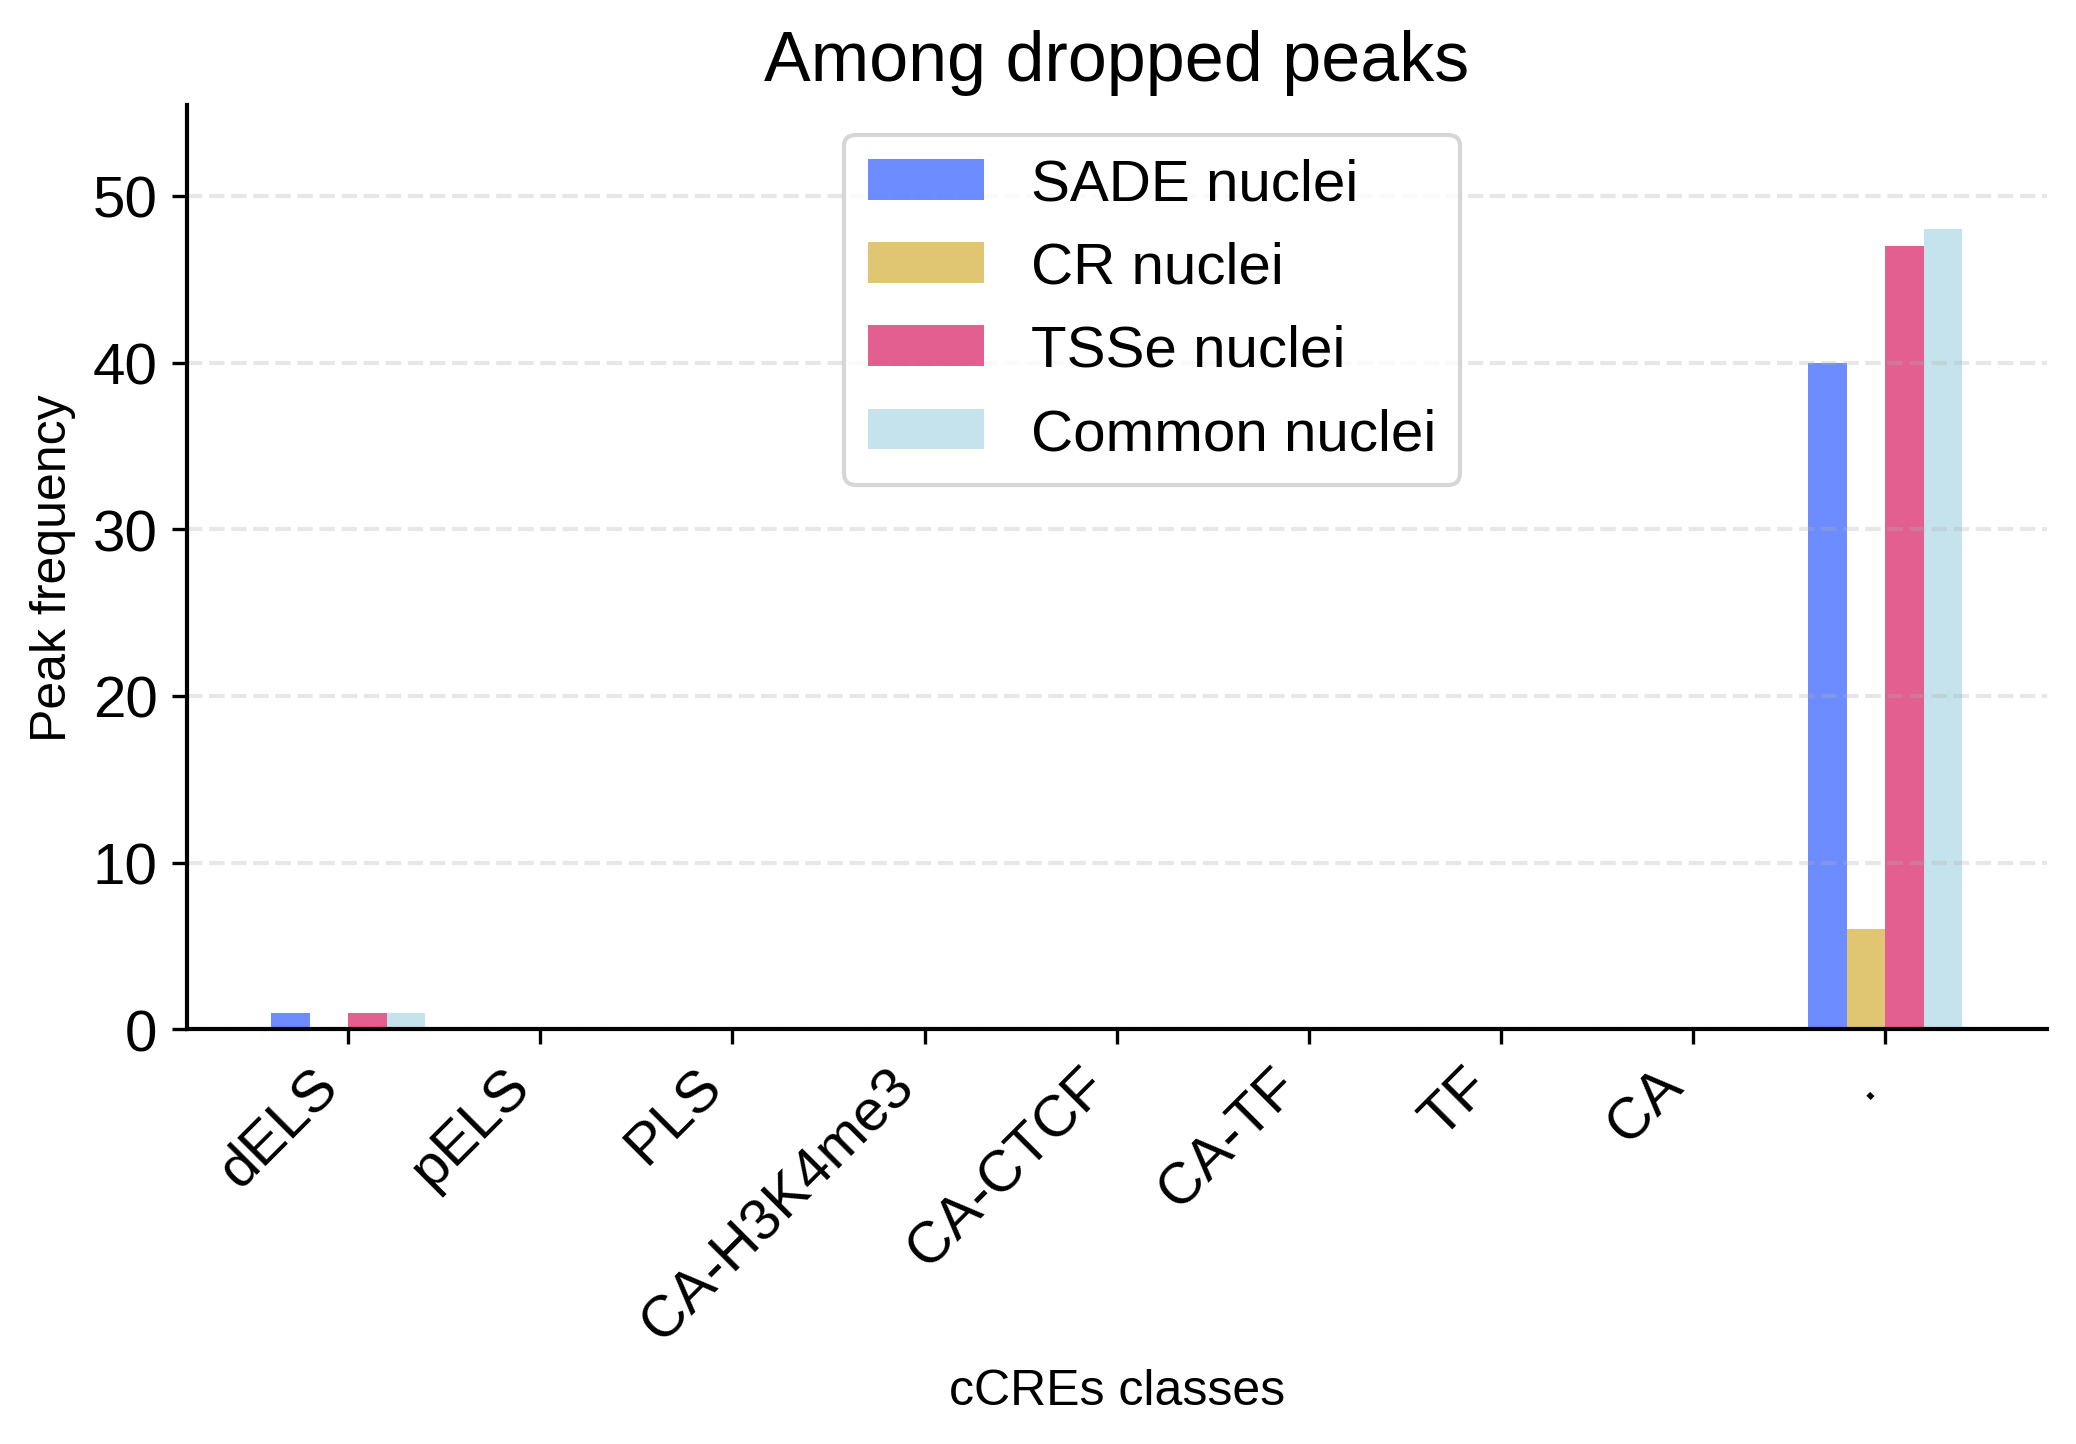

In [16]:
color_map = {'dELS': 'blue', 'pELS': 'orange', 'PLS': 'skyblue', 'CA-H3K4me3': 'red',
                "CA-CTCF": 'purple', 'CA-TF': 'brown', 'TF': 'pink', "CA": 'slateblue', '.': 'grey'}
index_map = {'dELS': 0, 'pELS': 1, 'PLS': 2, 'CA-H3K4me3': 3,
                "CA-CTCF": 4, 'CA-TF': 5, 'TF': 6, "CA": 7, '.': 8}

width = 0.2  # the width of the bars
fig, ax = plt.subplots( nrows=1, ncols=1, figsize=(8,4))

for d, c, poffset, l in zip([SADE_vs_raw_cCREs, CR_vs_raw_cCREs, TSSe_vs_raw_cCREs, common_vs_raw_cCREs], ['#2E5BFF', "#D4AF37", '#D81B60', 'lightblue'],
                    0.2*np.array([-1.5, -0.5, 0.5, 1.5]),
                    ['SADE nuclei', 'CR nuclei', 'TSSe nuclei', 'Common nuclei']):
    freq_df = d['dropped_peaks'].dropna(subset=['cCREs_class'], inplace=False
                                                 )['cCREs_class'].value_counts()
    x_positions = [index_map[idx] + poffset for idx in freq_df.index]
    bars = ax.bar(x_positions, freq_df.values, width=width, alpha=0.7, color=c, label=f'{l}')


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_ylabel('Peak frequency', fontsize=12)
ax.set_xlabel('cCREs classes', fontsize=12) 
ax.legend(loc='upper right', ncols=1, bbox_to_anchor=(0.7, 1))
ax.set_title('Among dropped peaks')


ticks = sorted(index_map.values())
labels = sorted(index_map, key=index_map.get)
ax.set_xticks(ticks)
ax.set_xticklabels(labels, rotation=45, ha='right')

In [17]:
SADEnewpeaks_vs_TSSenewpeaks = SADE_vs_raw_cCREs['newly_discovered_peaks'].merge(TSSe_vs_raw_cCREs['newly_discovered_peaks'], on='cCREs_accessionID2', suffixes=('_SADE', '_TSSe'), how='outer')
SADEnewpeaks_vs_TSSenewpeaks['Found_in_SADE'] = SADEnewpeaks_vs_TSSenewpeaks['overlap_bp_SADE'] > 0
SADEnewpeaks_vs_TSSenewpeaks['Found_in_TSSe'] = SADEnewpeaks_vs_TSSenewpeaks['overlap_bp_TSSe'] > 0
SADEnewpeaks_vs_TSSenewpeaks['overlap_bp_SADE'] = SADEnewpeaks_vs_TSSenewpeaks['overlap_bp_SADE'].fillna(0)
SADEnewpeaks_vs_TSSenewpeaks['overlap_bp_TSSe'] = SADEnewpeaks_vs_TSSenewpeaks['overlap_bp_TSSe'].fillna(0)
SADEnewpeaks_vs_TSSenewpeaks['cCREs_class'] = SADEnewpeaks_vs_TSSenewpeaks['cCREs_class_SADE'].fillna(SADEnewpeaks_vs_TSSenewpeaks['cCREs_class_TSSe'])

SADEnewpeaks_vs_TSSenewpeaks.columns

Index(['chrom_SADE', 'chromStart_SADE', 'chromEnd_SADE', 'name_SADE',
       'peak_auc_score_SADE', 'strand_SADE', 'signalValue_SADE', 'pValue_SADE',
       'qValue_SADE', 'peak_SADE', 'cCREs_chrom_SADE', 'cCREs_start_SADE',
       'cCREs_end_SADE', 'cCREs_acessionID1_SADE', 'cCREs_accessionID2',
       'cCREs_class_SADE', 'overlap_bp_SADE', 'chrom_TSSe', 'chromStart_TSSe',
       'chromEnd_TSSe', 'name_TSSe', 'peak_auc_score_TSSe', 'strand_TSSe',
       'signalValue_TSSe', 'pValue_TSSe', 'qValue_TSSe', 'peak_TSSe',
       'cCREs_chrom_TSSe', 'cCREs_start_TSSe', 'cCREs_end_TSSe',
       'cCREs_acessionID1_TSSe', 'cCREs_class_TSSe', 'overlap_bp_TSSe',
       'Found_in_SADE', 'Found_in_TSSe', 'cCREs_class'],
      dtype='object')

In [18]:
SADEnewpeaks_vs_TSSenewpeaks.groupby([ 'Found_in_SADE', 'Found_in_TSSe', 'cCREs_class', ]).size().unstack(fill_value=0)

cCREs_class                    .  CA  CA-CTCF  CA-H3K4me3  CA-TF   PLS  TF  \
Found_in_SADE Found_in_TSSe                                                  
False         False          400   0        0           0      0     0   0   
              True             0  40      109          82     10   341  48   
True          False            0   0        5           2      0    73   5   
              True             0  77      657         431     58  2767  66   

cCREs_class                   dELS  pELS  
Found_in_SADE Found_in_TSSe               
False         False              0     0  
              True            6234  1742  
True          False            680   527  
              True           35497  8195

---

In [19]:
SADEnewpeaks_vs_Commonnewpeaks = SADE_vs_raw_cCREs['newly_discovered_peaks'].merge(common_vs_raw_cCREs['newly_discovered_peaks'], on='cCREs_accessionID2', suffixes=('_SADE', '_Common'), how='outer')
SADEnewpeaks_vs_Commonnewpeaks['Found_in_SADE'] = SADEnewpeaks_vs_Commonnewpeaks['overlap_bp_SADE'] > 0
SADEnewpeaks_vs_Commonnewpeaks['Found_in_Common'] = SADEnewpeaks_vs_Commonnewpeaks['overlap_bp_Common'] > 0
SADEnewpeaks_vs_Commonnewpeaks['overlap_bp_SADE'] = SADEnewpeaks_vs_Commonnewpeaks['overlap_bp_SADE'].fillna(0)
SADEnewpeaks_vs_Commonnewpeaks['overlap_bp_Common'] = SADEnewpeaks_vs_Commonnewpeaks['overlap_bp_Common'].fillna(0)
SADEnewpeaks_vs_Commonnewpeaks['cCREs_class'] = SADEnewpeaks_vs_Commonnewpeaks['cCREs_class_SADE'].fillna(SADEnewpeaks_vs_Commonnewpeaks['cCREs_class_Common'])


In [20]:
SADEnewpeaks_vs_Commonnewpeaks.groupby([ 'Found_in_SADE', 'Found_in_Common', 'cCREs_class', ]).size().unstack(fill_value=0)

cCREs_class                      .  CA  CA-CTCF  CA-H3K4me3  CA-TF   PLS  TF  \
Found_in_SADE Found_in_Common                                                  
False         False            460   0        0           0      0     0   0   
              True               0  46      117          88     16   366  43   
True          False              0   1        4           2      0    66   5   
              True               0  76      658         431     58  2774  66   

cCREs_class                     dELS  pELS  
Found_in_SADE Found_in_Common               
False         False                0     0  
              True              6546  1773  
True          False              734   502  
              True             35444  8219

---